# Forecasting penggunaan CPU 120 jam ke depan (v3)

Notebook ini **berdiri sendiri**: data → kalender libur → pembersihan data kosong → pemilihan telemetri → fitur → validasi walk-forward → seleksi beku → test → evaluasi → prediksi probabilistik → biaya kapasitas → kontribusi telemetri → pra-registrasi uji konfirmasi.
Semua kode ada di notebook ini (tanpa modul lokal). Kode disembunyikan; klik sel untuk membukanya.

**Tujuan.** Memprediksi rata-rata penggunaan CPU per jam (%) untuk 1–120 jam ke depan dari setiap titik waktu (*origin*), sebagai dasar perencanaan kapasitas server (Saxena dkk., 2023).

**Status protokol.**
- Seleksi model hanya memakai periode **validation** (Mei–Agustus 2026).
- Periode **test** (September–Oktober 2026) sudah pernah dilihat di versi sebelumnya, sehingga hasil test di sini bersifat **eksploratori**.
- Bukti konfirmatori akan datang dari data **setelah 1 November 2026**. Nilai CPU pada data itu tidak dibaca di notebook ini dan disimpan untuk uji konfirmasi (bagian 12).

**Perbaikan dibanding versi sebelumnya**

| Masalah di v2 | Perbaikan di v3 |
|---|---|
| Kalender libur ditulis manual dan berhenti di 31 Des 2026 | Diambil dari library `holidays` (Indonesia: libur nasional dan cuti bersama), mencakup 2027 |
| Lubang CPU 1–2 jam menghapus sekitar 12 hari evaluasi; model jalan dengan fitur telemetri kosong | Pembersihan data kosong (bagian 3) dengan uji kebocoran |
| Memory, swap, dan process ikut dipakai padahal tidak stabil dan kini tidak lagi tercatat | Telemetri dipilih dengan aturan eksplisit (bagian 4) |
| Early stopping XGBoost tidak stabil (iterasi melompat 267 → 4) | Jumlah iterasi tetap untuk semua model boosting (bagian 6) |
| Target test 1–2 Nov 2026 ikut terpakai, padahal termasuk periode konfirmasi | Data dipotong di 1 Nov 2026 00:00 |
| Target origin validation akhir Agustus masuk ke periode test | Origin hanya dinilai bila seluruh 120 jam targetnya masih di dalam fasenya |
| Nama kode seperti "r3" dan "GLX" | Nama model dan set fitur ditulis lengkap |
| Block bootstrap kadang memberi CI tidak konsisten | Uji Diebold–Mariano untuk sampel kecil (Coroneo & Iacone, 2020) |

**Revisi 11 Nov 2026 (sesuai tiga tujuan skripsi).** Seleksi beku, model final, dan pra-registrasi **tidak berubah**; yang ditambah hanya analisis:

| Tujuan skripsi | Tambahan |
|---|---|
| 1. Model vs pembanding musiman | **Bagian 8.3**: Ridge musiman multivariat (model terbaik di pipeline awal) dinilai ulang sebagai pembanding linear, di luar seleksi beku |
| 2. Weighted loss untuk beban tinggi | **Bagian 8.4**: ensemble model final dilatih ulang dengan bobot 1 + λ pada jam CPU ≥ 80 % (λ = 1, 3, 9); trade-off MAE puncak vs MAE keseluruhan |
| 3. Stabilitas temporal (rolling origin) | **Tabel 12d–12e**: MAE relatif dan uji DM per bulan origin, koefisien variasi antarbulan |

Folder keluaran bawaan sekarang `outputs_v3_baru/` (folder lama `outputs_v3/` sudah dihapus).

Daftar pustaka ada di akhir notebook.

### Langkah dan dasar pustaka

| Langkah | Keputusan | Dasar |
|---|---|---|
| Skema evaluasi | Walk-forward (rolling origin), refit bulanan, hanya label yang sudah matang | Hyndman & Athanasopoulos (2021, §5.10); Cerqueira dkk. (2020); Hewamalage dkk. (2023) |
| Data kosong | Celah ≤ 3 jam diinterpolasi hanya untuk fitur; target tidak diimputasi | Hyndman & Athanasopoulos (2021, §13.9); Hewamalage dkk. (2023) |
| Kalender | Dummy libur nasional dan cuti bersama, jam, hari | Hyndman & Athanasopoulos (2021, §7.4, §13.1) |
| Telemetri | Dibuang bila tidak lagi tersedia atau tidak stabil; korelasi hanya dilaporkan | Hewamalage dkk. (2023); Bayram dkk. (2022); Hyndman & Athanasopoulos (2021, §7.5) |
| Fitur lag dan rolling | Lag, rata-rata bergerak, pola mingguan | Januschowski dkk. (2022); Makridakis dkk. (2022a) |
| Target residual | Model belajar selisih terhadap pola 4 minggu (deseasonalisasi) | Hewamalage, Bergmeir & Bandara (2021) |
| Pembanding | Naif musiman mingguan dan rata-rata 4 minggu | Hyndman & Athanasopoulos (2021, §5.2); Hewamalage dkk. (2023) |
| Model | Ridge; HistGradientBoosting, LightGBM, XGBoost | James dkk. (2021, §6.2); Bentéjac dkk. (2021); Januschowski dkk. (2022) |
| Loss | L1 (absolute error), karena metrik utama MAE | Kolassa (2020) |
| Bobot waktu | Bobot eksponensial untuk data lama (half-life) | Hyndman & Athanasopoulos (2021, §8.1); Bayram dkk. (2022) |
| Pembanding linear | Ridge musiman multivariat (dummy jam dan hari + fitur yang sama), di luar seleksi beku | James dkk. (2021, §6.2); Hyndman & Athanasopoulos (2021, §7.4) |
| Weighted loss puncak | Bobot sampel 1 + λ·1[CPU ≥ 80 %] pada loss L1; trade-off MAE puncak vs MAE keseluruhan | Ribeiro & Moniz (2020); Kolassa (2020) |
| Stabilitas temporal | MAE relatif dan uji DM per bulan origin (rolling origin), koefisien variasi | Cerqueira dkk. (2020); Hewamalage dkk. (2023); Coroneo & Iacone (2020) |
| Iterasi boosting | Tetap (300, learning rate 0,05), tanpa early stopping | Bentéjac dkk. (2021) |
| Ensemble | Rata-rata sederhana tiga model boosting | Wang dkk. (2023); Hyndman & Athanasopoulos (2021, §13.4) |
| Metrik | MAE, RMSE, bias, MAE relatif terhadap pembanding | Hyndman & Athanasopoulos (2021, §5.8); Hewamalage dkk. (2023) |
| Uji beda akurasi | Diebold–Mariano dengan estimator periodogram Daniell, m = ⌊T^(1/3)⌋, distribusi t(2m) | Coroneo & Iacone (2020) |
| Prediksi probabilistik | LightGBM kuantil (7 kuantil) | Januschowski dkk. (2022); Makridakis dkk. (2022b); Rossi dkk. (2025) |
| Kalibrasi interval | Kalibrasi konformal sekuensial dengan galat yang sudah matang (28 hari) | Xu & Xie (2023) |
| Evaluasi probabilistik | Skor kuantil, cakupan, lebar, skor Winkler | Hyndman & Athanasopoulos (2021, §5.9); Makridakis dkk. (2022b) |
| Biaya kapasitas | Biaya asimetris; kuantil optimal τ = k/(k + 1) | Eramo dkk. (2020); Kolassa (2020) |
| Kontribusi fitur | TreeSHAP per refit bulanan | Lundberg dkk. (2020); Bayram dkk. (2022) |

## 0. Konfigurasi

In [1]:
DATA_PATH   = "cleaned_unimputed.csv"
OUT_DIR     = __import__("os").environ.get("OUT_DIR", "outputs_v3_baru")   # folder seleksi beku terbaru; override lewat env OUT_DIR
DATA_CUTOFF = "2026-11-01 00:00"      # baris sesudah ini = data konfirmasi; nilainya tidak dibaca
H, HIGH     = 120, 80.0               # horizon (jam) dan ambang beban tinggi (%)
TRAIN_STRIDE, SCORE_STRIDE = 2, 6     # jarak origin training dan origin yang dinilai (jam)
SPLIT = {"validation": {"refits": ["2026-05-01", "2026-06-01", "2026-07-01", "2026-08-01"], "end": "2026-09-01"},
         "test":       {"refits": ["2026-09-01", "2026-10-01"], "end": DATA_CUTOFF}}
MAX_GAP, MIN_TARGET = 3, 0.95         # pembersihan: celah <= 3 jam diinterpolasi; origin dinilai bila >= 95% target teramati
MAX_MISSING_PCT = 1.0                 # telemetri "sering kosong" bila > 1% jam kosong
N_ITER, LR = 300, 0.05                # iterasi tetap untuk semua boosting
SEED, N_JOBS, N_DM_MIN = 42, 6, 20
REUSE_CACHE = True
# Tambahan bagian 9-11: prediksi probabilistik, biaya kapasitas, kontribusi telemetri
SPLIT_ALL = {"kalibrasi": {"refits": ["2026-04-01"], "end": "2026-05-01"}, **SPLIT}   # April = riwayat kalibrasi, tidak dinilai
QLEVELS = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]       # kuantil yang diprediksi
WINDOW_DAYS, MIN_CAL = 28, 50                             # jendela galat matang untuk kalibrasi konformal; minimal galat per pita horizon
K_COST = [1, 3, 9, 19]                                    # rasio biaya kekurangan : kelebihan kapasitas -> kuantil optimal k/(k+1)
N_SHAP = 6000                                             # baris acak per refit untuk TreeSHAP
PEAK_LAMBDAS = [0, 1, 3, 9]                               # bagian 8.4: bobot jam CPU >= 80 % = 1 + lambda (0 = model final apa adanya)
RIDGE_ALPHAS = (10.0, 100.0, 1000.0)                      # bagian 8.3: grid alpha Ridge (pembanding linear)

import os, json, time, pickle, hashlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
import holidays, sklearn, lightgbm as lgb, xgboost as xgb
from scipy import stats
from IPython.display import display, Markdown
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
warnings.filterwarnings("ignore")
os.makedirs(f"{OUT_DIR}/figures", exist_ok=True); os.makedirs(f"{OUT_DIR}/cache", exist_ok=True)

TARGET = "cpu_usage_percent"
METRICS = ["cpu_usage_percent", "sysload_1m", "sysload_5m", "sysload_15m", "memory_usage_percent", "swap_usage_percent",
           "network_rx_bytes_per_sec", "network_tx_bytes_per_sec", "disk_read_bytes_per_sec", "disk_write_bytes_per_sec",
           "disk_read_iops", "disk_write_iops", "process_running_count", "process_blocked_count"]
TELE_ALL = ["sysload_1m", "sysload_15m", "memory_usage_percent", "swap_usage_percent", "network_rx_bytes_per_sec", "network_tx_bytes_per_sec",
            "disk_read_bytes_per_sec", "disk_write_bytes_per_sec", "disk_read_iops", "disk_write_iops", "process_running_count", "process_blocked_count"]
LOG_COLS = {c for c in TELE_ALL if "bytes" in c or "iops" in c or "process" in c}
TELE_LONG = ("sysload_15m", "disk_read_iops")      # telemetri yang juga diberi rata-rata dan deviasi 168 jam
VERSIONS = {"holidays": holidays.__version__, "scikit-learn": sklearn.__version__, "lightgbm": lgb.__version__, "xgboost": xgb.__version__,
            "pandas": pd.__version__, "numpy": np.__version__}
DEVICE  = os.environ.get("ML_DEVICE", "gpu")      # "gpu": XGBoost CUDA + LightGBM GPU; "cpu": semua di CPU. HGB & Ridge (sklearn) selalu CPU
XGB_DEV = {"device": "cuda"} if DEVICE == "gpu" else {}
def _lgb_gpu_ok():                                  # wheel PyPI LightGBM tidak dibangun dengan GPU: bila begitu LightGBM tetap di CPU
    try:
        import numpy as _np, lightgbm as _lgb
        _lgb.train({"device_type": "gpu", "verbose": -1}, _lgb.Dataset(_np.random.rand(200, 2), _np.random.rand(200)), 1); return True
    except Exception: return False
LGB_DEV = {"device_type": "gpu"} if DEVICE == "gpu" and _lgb_gpu_ok() else {}
print(f"Perangkat: XGBoost {'cuda' if XGB_DEV else 'cpu'}, LightGBM {'gpu' if LGB_DEV else 'cpu'}, HGB/Ridge cpu")
xgb.set_config(verbosity=0)                        # sembunyikan peringatan "mismatched devices" saat predict dari array CPU
VERSIONS["device"] = f"xgb:{'cuda' if XGB_DEV else 'cpu'}, lgbm:{'gpu' if LGB_DEV else 'cpu'}"                         # ikut kunci cache: hasil CPU dan GPU tidak tercampur

FAM = {"ridge": "Ridge", "hgb": "HistGradientBoosting", "lgbm": "LightGBM", "xgb": "XGBoost", "lgbm_q": "LightGBM kuantil"}
FS = {"cpu": "CPU + kalender", "tele": "CPU + kalender + telemetri terpilih"}
BASE = {"snaive": "Naif musiman mingguan", "mean4w": "Rata-rata 4 minggu"}
COL = {"cpu": "#6250d6", "tele": "#eb6834", "mean4w": "#52514e", "x1": "#2a78d6", "x2": "#1baf7a"}   # dicek dengan validator palet (CVD)
INK, INK2, GRID, BAND = "#0b0b0b", "#52514e", "#e6e5e0", "#f1f0eb"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": .6, "font.size": 9, "axes.titlesize": 10, "axes.titlelocation": "left"})
FASE = {"validation": "Validation", "test": "Test"}
def show(df, fmt=None, caption=None):
    st = df.style.hide(axis="index").format(fmt or None, na_rep="–", precision=2, escape="html")
    if caption: st = st.set_caption(caption).set_table_styles([{"selector": "caption", "props": "caption-side: top; font-weight: 600; text-align: left;"}])
    display(st)
def sha_file(p): return hashlib.sha256(open(p, "rb").read()).hexdigest()
def sha_obj(o): return hashlib.sha256(json.dumps(o, sort_keys=True, default=str).encode()).hexdigest()
show(pd.DataFrame({"Pustaka": list(VERSIONS), "Versi": list(VERSIONS.values())}), caption="Versi pustaka yang dipakai")

Perangkat: XGBoost cuda, LightGBM cpu, HGB/Ridge cpu


Pustaka,Versi
holidays,0.108
scikit-learn,1.9.1
lightgbm,4.7.0
xgboost,3.2.0
pandas,3.1.1
numpy,2.4.6
device,"xgb:cuda, lgbm:cpu"


## 1. Data

Data per jam dengan timestamp di akhir interval: baris *t* adalah rata-rata dari (t − 1 jam, t].
Duplikat yang berkonflik ditolak, grid jam dilengkapi, dan rentang nilai dicek.
Baris setelah **1 Nov 2026 00:00** dipisahkan untuk uji konfirmasi. Dari baris itu yang dibaca hanya **ketersediaan kolom**, bukan nilainya.

In [2]:
raw = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
assert not (set(["timestamp", *METRICS]) - set(raw.columns)), "kolom hilang"
assert raw.timestamp.dt.tz is None, "timestamp harus tanpa zona waktu (WIB lokal)"
for c in METRICS: raw[c] = pd.to_numeric(raw[c], errors="raise").astype(float)
dup = raw[raw.timestamp.duplicated(keep=False)]
assert not any(g[c].dropna().nunique() > 1 for _, g in dup.groupby("timestamp") for c in METRICS), "duplikat berkonflik"
full = raw.sort_values("timestamp").groupby("timestamp")[METRICS].first()
full = full.reindex(pd.date_range(full.index.min(), full.index.max(), freq="h", name="timestamp"))
for c in ("cpu_usage_percent", "memory_usage_percent", "swap_usage_percent"):
    assert full[c].dropna().between(0, 100).all(), f"{c} di luar 0-100"
assert (full[[c for c in METRICS if "percent" not in c]].fillna(0) >= 0).all().all(), "metrik negatif"

cut = pd.Timestamp(DATA_CUTOFF)
NEW_AVAIL = full.loc[full.index > cut, TELE_ALL].notna().mean()      # hanya ketersediaan, bukan nilai
n_new = int((full.index > cut).sum())
df = full.loc[:cut].copy()                                             # data yang dipakai notebook ini
DATA_SHA = sha_file(DATA_PATH)

per = {"Training awal": (df.index.min(), pd.Timestamp("2026-05-01")), "Validation": (pd.Timestamp("2026-05-01"), pd.Timestamp("2026-09-01")),
       "Test": (pd.Timestamp("2026-09-01"), cut + pd.Timedelta(hours=1))}
def pmask(p): a, b = per[p]; return (df.index >= a) & (df.index < b)
rows = []
for p in per:
    c = df.loc[pmask(p), TARGET]
    rows.append({"Periode": p, "Dari": f"{c.index.min():%d %b %Y %H:%M}", "Sampai": f"{c.index.max():%d %b %Y %H:%M}", "Jam": len(c),
                 "CPU kosong (jam)": int(c.isna().sum()), "Rata-rata CPU (%)": c.mean(), "SD": c.std(), "Jam CPU ≥ 80% (%)": 100 * (c >= HIGH).mean()})
rows.append({"Periode": "Disimpan untuk konfirmasi", "Dari": f"{full.index[full.index > cut].min():%d %b %Y %H:%M}" if n_new else "–",
             "Sampai": f"{full.index.max():%d %b %Y %H:%M}", "Jam": n_new, "CPU kosong (jam)": np.nan, "Rata-rata CPU (%)": np.nan, "SD": np.nan, "Jam CPU ≥ 80% (%)": np.nan})
show(pd.DataFrame(rows), {"Jam": "{:,.0f}", "CPU kosong (jam)": "{:.0f}", "Rata-rata CPU (%)": "{:.1f}", "SD": "{:.1f}", "Jam CPU ≥ 80% (%)": "{:.1f}"},
     "Tabel 1. Ringkasan data per periode")
display(Markdown(f"Sumber data: `{DATA_PATH}`, sha256 `{DATA_SHA[:16]}…`"))

Periode,Dari,Sampai,Jam,CPU kosong (jam),Rata-rata CPU (%),SD,Jam CPU ≥ 80% (%)
Training awal,16 Oct 2025 00:00,30 Apr 2026 23:00,"4,728",2,35.7,20.8,4.0
Validation,01 May 2026 00:00,31 Aug 2026 23:00,"2,952",3,40.2,21.8,6.5
Test,01 Sep 2026 00:00,01 Nov 2026 00:00,"1,465",1,41.2,17.4,1.9
Disimpan untuk konfirmasi,01 Nov 2026 01:00,03 Nov 2026 00:00,48,–,–,–,–


Sumber data: `cleaned_unimputed.csv`, sha256 `3db8308fca2c5623…`

## 2. Kalender libur Indonesia

Libur diambil dari library `holidays` dengan dua kategori: **public** (libur nasional) dan **government** (cuti bersama), karena keduanya mengubah pola kerja pengguna server (Hyndman & Athanasopoulos, 2021, §7.4).
Kalender memakai tanggal **awal** interval, jadi baris 00:00 mengikuti hari sebelumnya.
Fitur turunannya: libur nasional, cuti bersama, dan jarak (hari) ke atau dari hari libur terdekat, dibatasi 14 hari.

In [3]:
YEARS = list(range(df.index.year.min() - 1, df.index.year.max() + 2))
HOL_PUB = holidays.country_holidays("ID", years=YEARS)
HOL_GOV = holidays.country_holidays("ID", years=YEARS, categories=("government",))
cal = pd.DataFrame(0, index=pd.date_range(f"{YEARS[0]}-01-01", f"{YEARS[-1]}-12-31"), columns=["libur_nasional", "cuti_bersama"])
cal["libur_nasional"] = [int(d in HOL_PUB) for d in cal.index.date]
cal["cuti_bersama"] = [int(d in HOL_GOV) for d in cal.index.date]
off = (cal.libur_nasional + cal.cuti_bersama).gt(0).to_numpy(); i = np.arange(len(cal)); op = i[off]
nx = np.searchsorted(op, i, side="left"); pv = np.searchsorted(op, i, side="right") - 1
cal["hari_ke_libur"] = np.clip(np.where(nx < len(op), op[np.minimum(nx, len(op) - 1)] - i, 99), 0, 14)
cal["hari_sejak_libur"] = np.clip(np.where(pv >= 0, i - op[np.maximum(pv, 0)], 99), 0, 14)
a, b = df.index.min().normalize(), (df.index.max() + pd.Timedelta(days=6)).normalize()
hl = [(d, "Libur nasional", n) for d, n in HOL_PUB.items() if a.date() <= d <= b.date()] + [(d, "Cuti bersama", n) for d, n in HOL_GOV.items() if a.date() <= d <= b.date()]
ht = pd.DataFrame(sorted(hl), columns=["Tanggal", "Jenis", "Nama"]); ht["Tanggal"] = pd.to_datetime(ht.Tanggal).dt.strftime("%a %d %b %Y")
show(ht, caption=f"Tabel 2. Hari libur dan cuti bersama dalam periode data (library holidays {holidays.__version__})")
n27 = sum(1 for d in list(HOL_PUB) + list(HOL_GOV) if d.year == 2027)
display(Markdown(f"Kalender juga mencakup tahun {YEARS[-1]} ({n27} hari libur dan cuti bersama), sehingga target uji konfirmasi setelah 31 Des 2026 tetap bisa dibuat."))

Tanggal,Jenis,Nama
Thu 25 Dec 2025,Libur nasional,Hari Raya Natal
Fri 26 Dec 2025,Cuti bersama,Cuti Bersama Hari Raya Natal
Thu 01 Jan 2026,Libur nasional,Tahun Baru Masehi
Fri 16 Jan 2026,Libur nasional,Isra Mikraj Nabi Muhammad
Mon 16 Feb 2026,Cuti bersama,Cuti Bersama Tahun Baru Imlek
Tue 17 Feb 2026,Libur nasional,Tahun Baru Imlek
Wed 18 Mar 2026,Cuti bersama,Cuti Bersama Hari Suci Nyepi
Thu 19 Mar 2026,Libur nasional,Hari Suci Nyepi
Fri 20 Mar 2026,Cuti bersama,Cuti Bersama Hari Raya Idul Fitri
Sat 21 Mar 2026,Libur nasional,Hari Raya Idul Fitri


Kalender juga mencakup tahun 2027 (26 hari libur dan cuti bersama), sehingga target uji konfirmasi setelah 31 Des 2026 tetap bisa dibuat.

## 3. Pembersihan data kosong

Aturan pembersihan (Hyndman & Athanasopoulos, 2021, §13.9; Hewamalage dkk., 2023):

| Aturan | Isi |
|---|---|
| C1 | Celah pendek (≤ 3 jam berturut-turut) diinterpolasi linear, **hanya untuk input fitur**. Celah lebih panjang tidak diimputasi dan dianggap *outage*. |
| C2 | Origin dinilai bila CPU teramati di jam origin, riwayat CPU 169 jam lengkap setelah C1, dan ≥ 95% dari 120 target teramati. Galat dihitung hanya pada target yang **teramati**: nilai CPU yang dinilai tidak pernah diimputasi. |
| C3 | Model dengan telemetri hanya dipakai di origin *t* bila semua telemetri terpilih teramati di jam *t* dan tidak ada outage di jendela fiturnya (168 jam untuk fitur 168 jam, 48 jam untuk lainnya). Selain itu dipakai model **CPU + kalender** dari keluarga yang sama (*fallback*). |

**Kausalitas.** Model hanya memakai metrik yang teramati di jam origin. Karena itu setiap celah sebelum origin sudah tertutup, sehingga panjang celah dan nilai interpolasinya hanya bergantung pada data sampai origin. Uji kebocoran di bagian 5 memeriksa ini.

In [4]:
def gap_runs(d):
    rows = []
    for c in d.columns:
        na = d[c].isna()
        if not na.any(): continue
        g = (na != na.shift()).cumsum()
        for _, s in d.index[na].to_series().groupby(g[na]): rows.append({"kolom": c, "mulai": s.iloc[0], "selesai": s.iloc[-1], "jam": len(s)})
    return pd.DataFrame(rows, columns=["kolom", "mulai", "selesai", "jam"])

def impute_short(d, max_gap=MAX_GAP):
    out = d.copy()
    for c in d.columns:
        na = d[c].isna()
        if not na.any(): continue
        run = na.groupby((na != na.shift()).cumsum()).transform("sum")
        fill = d[c].interpolate(method="time", limit_area="inside")
        short = na & (run <= max_gap) & fill.notna()
        out.loc[short, c] = fill[short]
    return out

FEAT_DF = impute_short(df[METRICS])
gaps = gap_runs(df[METRICS])
ev = gaps.groupby(["mulai", "selesai", "jam"]).kolom.apply(list).reset_index()
show(pd.DataFrame({"Mulai": ev.mulai.dt.strftime("%d %b %Y %H:%M"), "Selesai": ev.selesai.dt.strftime("%d %b %Y %H:%M"), "Jam": ev.jam,
                   "Metrik kosong": ev.kolom.apply(len), "CPU ikut kosong": ev.kolom.apply(lambda k: "ya" if TARGET in k else "tidak"),
                   "Tindakan": np.where(ev.jam <= MAX_GAP, "C1: diinterpolasi untuk fitur", "outage: tidak diimputasi")}),
     {"Jam": "{:d}", "Metrik kosong": "{:d}"}, f"Tabel 3. Semua celah data sampai {DATA_CUTOFF} ({len(METRICS)} metrik)")

Mulai,Selesai,Jam,Metrik kosong,CPU ikut kosong,Tindakan
02 Feb 2026 20:00,02 Feb 2026 20:00,1,8,ya,C1: diinterpolasi untuk fitur
03 Feb 2026 11:00,03 Feb 2026 11:00,1,8,ya,C1: diinterpolasi untuk fitur
14 Jun 2026 01:00,14 Jun 2026 02:00,2,14,ya,C1: diinterpolasi untuk fitur
16 Aug 2026 01:00,16 Aug 2026 01:00,1,14,ya,C1: diinterpolasi untuk fitur
05 Oct 2026 19:00,05 Oct 2026 19:00,1,14,ya,C1: diinterpolasi untuk fitur
19 Oct 2026 14:00,21 Oct 2026 23:00,58,4,tidak,outage: tidak diimputasi
29 Oct 2026 01:00,01 Nov 2026 00:00,72,4,tidak,outage: tidak diimputasi


## 4. Pemilihan telemetri

Sebuah metrik telemetri **dibuang** bila memenuhi salah satu syarat berikut:
- **Tidak lagi tersedia:** kosong di data baru setelah 1 Nov 2026. Model operasional hanya boleh memakai input yang tersedia saat prediksi dibuat (Hewamalage dkk., 2023).
- **Sering kosong:** lebih dari 1% jam kosong sampai batas data.
- **Korelasi dengan CPU termasuk dua terendah** di periode training awal. Ini adalah syarat dari pengguna untuk memory dan swap.

Hyndman & Athanasopoulos (2021, §7.5) mengingatkan bahwa korelasi saja bukan dasar yang sah untuk memilih prediktor. Karena itu korelasi di sini hanya dilaporkan sebagai bukti pendukung. Alasan utamanya adalah ketersediaan dan stabilitas: perubahan perilaku metrik antarperiode adalah bentuk *concept drift* yang menurunkan kinerja model (Bayram dkk., 2022).
Korelasi dihitung hanya dari periode training awal, tanpa melihat periode validation dan test.

In [5]:
crit = pd.DataFrame({"Metrik": TELE_ALL})
crit["Kosong s.d. batas data (%)"] = [100 * df[m].isna().mean() for m in TELE_ALL]
crit["Terisi di data baru (%)"] = [100 * NEW_AVAIL[m] for m in TELE_ALL]
crit["Korelasi Spearman dgn CPU (training awal)"] = [df.loc[pmask("Training awal"), [m, TARGET]].corr(method="spearman").iloc[0, 1] for m in TELE_ALL]
low = crit.nsmallest(2, "Korelasi Spearman dgn CPU (training awal)").Metrik.tolist()
def why(r):
    a = []
    if r["Terisi di data baru (%)"] < 95: a.append("tidak lagi tersedia")
    if r["Kosong s.d. batas data (%)"] > MAX_MISSING_PCT: a.append(f"sering kosong (> {MAX_MISSING_PCT:g}%)")
    if r.Metrik in low: a.append("korelasi termasuk dua terendah")
    return ", ".join(a)
crit["Alasan dibuang"] = crit.apply(why, axis=1); crit["Dipakai"] = np.where(crit["Alasan dibuang"] == "", "ya", "tidak")
TELE = [m for m in TELE_ALL if crit.set_index("Metrik").loc[m, "Dipakai"] == "ya"]
show(crit.sort_values("Korelasi Spearman dgn CPU (training awal)"),
     {"Kosong s.d. batas data (%)": "{:.2f}", "Terisi di data baru (%)": "{:.0f}", "Korelasi Spearman dgn CPU (training awal)": "{:.2f}"},
     "Tabel 4. Kriteria pemilihan telemetri")
assert not {"memory_usage_percent", "swap_usage_percent", "process_running_count", "process_blocked_count"} & set(TELE), "metrik terlarang ikut terpilih"
display(Markdown(f"**Telemetri terpilih ({len(TELE)}):** {', '.join(TELE)}"))

Metrik,Kosong s.d. batas data (%),Terisi di data baru (%),Korelasi Spearman dgn CPU (training awal),Alasan dibuang,Dipakai
swap_usage_percent,1.49,0,0.16,"tidak lagi tersedia, sering kosong (> 1%), korelasi termasuk dua terendah",tidak
memory_usage_percent,1.49,0,0.38,"tidak lagi tersedia, sering kosong (> 1%), korelasi termasuk dua terendah",tidak
network_tx_bytes_per_sec,0.04,100,0.43,,ya
network_rx_bytes_per_sec,0.04,100,0.47,,ya
disk_write_bytes_per_sec,0.04,100,0.67,,ya
disk_write_iops,0.04,100,0.72,,ya
disk_read_iops,0.04,100,0.75,,ya
disk_read_bytes_per_sec,0.04,100,0.76,,ya
process_blocked_count,1.49,0,0.77,"tidak lagi tersedia, sering kosong (> 1%)",tidak
process_running_count,1.49,0,0.88,"tidak lagi tersedia, sering kosong (> 1%)",tidak


**Telemetri terpilih (8):** sysload_1m, sysload_15m, network_rx_bytes_per_sec, network_tx_bytes_per_sec, disk_read_bytes_per_sec, disk_write_bytes_per_sec, disk_read_iops, disk_write_iops

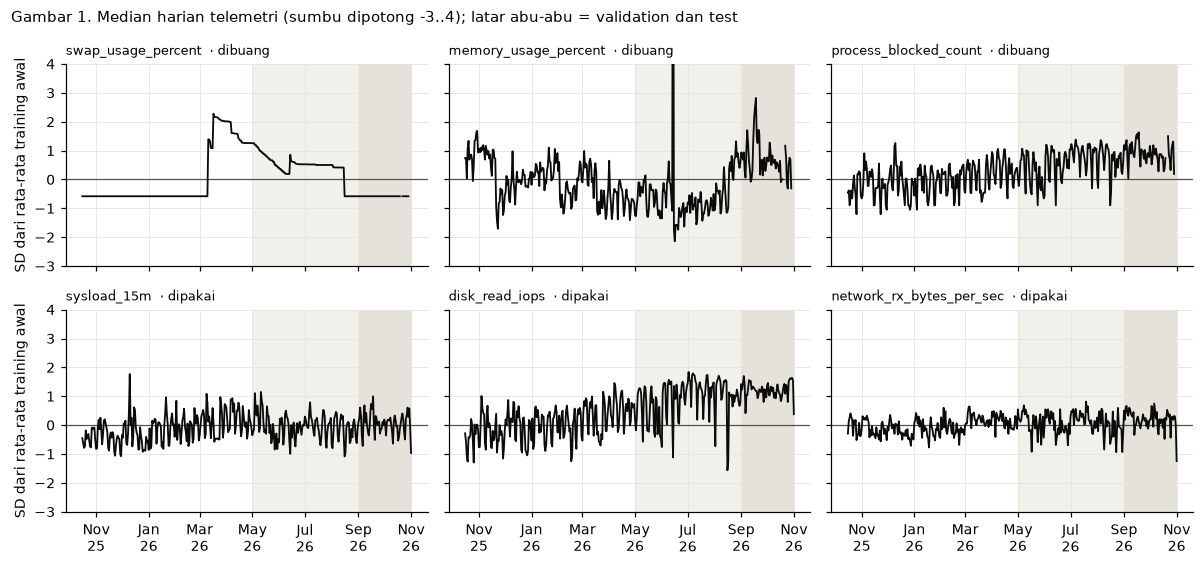

In [6]:
# Gambar 1: perilaku metrik yang dibuang vs yang dipakai (median harian, dalam SD training awal)
show_m = ["swap_usage_percent", "memory_usage_percent", "process_blocked_count", "sysload_15m", "disk_read_iops", "network_rx_bytes_per_sec"]
fig, axs = plt.subplots(2, 3, figsize=(11, 5.2), sharex=True, sharey=True)
for ax, m in zip(axs.ravel(), show_m):
    v = np.log1p(df[m].clip(lower=0)) if m in LOG_COLS else df[m]; t0 = v[pmask("Training awal")]
    z = ((v - t0.mean()) / (t0.std() or 1.0)).resample("D").median()
    for p_, c in (("Validation", BAND), ("Test", "#e4e2da")): ax.axvspan(per[p_][0], per[p_][1], color=c, lw=0, zorder=0)
    ax.axhline(0, color=INK2, lw=.8); ax.plot(z.index, z.values, color=INK, lw=1.2)
    ax.set_title(m + ("  · dipakai" if m in TELE else "  · dibuang"), fontsize=8.5)
axs[0, 0].set_ylim(-3, 4)
for ax in axs[:, 0]: ax.set_ylabel("SD dari rata-rata training awal")
for ax in axs[-1]: ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%y"))
fig.suptitle("Gambar 1. Median harian telemetri (sumbu dipotong -3..4); latar abu-abu = validation dan test", x=.01, ha="left", fontsize=10)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/figures/01_telemetri.png"); plt.show()

## 5. Fitur, origin, dan uji kebocoran

Semua fitur hanya memakai data sampai origin *t*.
- **CPU:** nilai saat ini, lag 1–168 jam, statistik rolling 24/72/168 jam, tren 168 vs 672 jam, perubahan minggu ke minggu, dan jumlah jam ≥ 80%. Fitur lag dan rolling seperti ini adalah praktik baku pada model pohon untuk forecasting (Januschowski dkk., 2022; Makridakis dkk., 2022a).
- **Pola musiman:** nilai CPU pada jam yang sama 1–4 minggu sebelumnya, rata-ratanya, profil jam-minggu, dan anomali saat origin terhadap profil itu. Data per jam punya pola harian dan mingguan sekaligus (Hyndman & Athanasopoulos, 2021, §13.1).
- **Kalender pada waktu target:** jam, hari, akhir pekan, libur nasional, cuti bersama, dan jarak ke libur (§7.4).
- **Horizon** *h* (1–120). Satu model melayani semua horizon (strategi *direct* multi-horizon).
- **Telemetri terpilih:** nilai saat ini, rata-rata 24 jam, dan lag 24 jam. Untuk sysload_15m dan disk_read_iops ditambah rata-rata dan deviasi 168 jam. Metrik byte, IOPS, dan proses memakai skala log.

In [7]:
CPU_LAGS = (1, 2, 3, 6, 12, 24, 48, 72, 168); ROLLS = (24, 72, 168)
def how(ix): s = ix - pd.Timedelta(hours=1); return (s.dayofweek * 24 + s.hour).to_numpy()

def origin_features(d):
    c = d[TARGET]; out = {"cpu_now": c}
    for l in CPU_LAGS: out[f"cpu_lag_{l}"] = c.shift(l)
    for w in ROLLS:
        r = c.rolling(w, min_periods=w)
        out[f"cpu_mean_{w}"], out[f"cpu_std_{w}"], out[f"cpu_max_{w}"], out[f"cpu_min_{w}"] = r.mean(), r.std(ddof=0), r.max(), r.min()
    out["cpu_diff_1"] = c - c.shift(1)
    hi = c.ge(HIGH).astype(float).where(c.notna())
    out["cpu_jam_ge80_24"] = hi.rolling(24, min_periods=24).sum(); out["cpu_jam_ge80_168"] = hi.rolling(168, min_periods=160).sum()
    m672 = c.rolling(672, min_periods=600).mean()
    out["cpu_mean_672"] = m672; out["cpu_tren_168_672"] = out["cpu_mean_168"] - m672
    out["cpu_wow_24"] = out["cpu_mean_24"] - out["cpu_mean_24"].shift(168); out["cpu_wow_168"] = out["cpu_mean_168"] - out["cpu_mean_168"].shift(168)
    out["cpu_diff_168"] = c - c.shift(168)
    for m in TELE:
        v = np.log1p(d[m].clip(lower=0)) if m in LOG_COLS else d[m]
        out[f"tele_{m}_now"] = v; out[f"tele_{m}_mean_24"] = v.rolling(24, min_periods=18).mean(); out[f"tele_{m}_lag_24"] = v.shift(24)
        if m in TELE_LONG:
            r = v.rolling(168, min_periods=150).mean(); out[f"tele_{m}_mean_168"] = r; out[f"tele_{m}_dev_168"] = v - r
    s = d.index - pd.Timedelta(hours=1)
    out["origin_jam"] = pd.Series(s.hour, index=d.index).astype(float); out["origin_hari"] = pd.Series(s.dayofweek, index=d.index).astype(float)
    return pd.DataFrame(out, index=d.index)

def how_profile(c):
    """prof[i,k] = rata-rata CPU pada baris <= i dengan jam-minggu k (ekspansif, kausal)."""
    hw = how(c.index); v = c.to_numpy(float); ok = np.isfinite(v)
    oh = np.zeros((len(v), 168)); oh[np.arange(len(v))[ok], hw[ok]] = 1.0
    sums = np.cumsum(oh * np.where(ok, v, 0)[:, None], axis=0); cnt = np.cumsum(oh, axis=0)
    with np.errstate(invalid="ignore", divide="ignore"): return np.where(cnt > 0, sums / cnt, np.nan)

META = ("origin", "target_time", "y")
def build_rows(d, of, prof, origins, y_raw):
    pos = d.index.get_indexer(origins); assert (pos >= 0).all()
    n = len(origins); P = np.repeat(pos, H); Hh = np.tile(np.arange(1, H + 1), n); tp = P + Hh
    cp = d[TARGET].to_numpy(float); N = len(cp)
    X = pd.DataFrame(of.to_numpy(np.float32)[P], columns=of.columns); X["h"] = Hh.astype(np.float32)
    tt = d.index[0] + pd.to_timedelta(tp, unit="h"); s = tt - pd.Timedelta(hours=1); dd = s.normalize()
    assert dd.isin(cal.index).all(), "kalender tidak mencakup tanggal target"
    X["t_jam"] = s.hour; X["t_hari"] = s.dayofweek; X["t_jam_sin"] = np.sin(2 * np.pi * s.hour / 24); X["t_jam_cos"] = np.cos(2 * np.pi * s.hour / 24)
    X["t_akhir_pekan"] = (s.dayofweek >= 5).astype(float)
    for c_ in ("libur_nasional", "cuti_bersama", "hari_ke_libur", "hari_sejak_libur"): X[f"t_{c_}"] = cal[c_].reindex(dd).to_numpy(float)
    X["t_tanggal"] = s.day; X["t_hari_ke_akhir_bulan"] = s.days_in_month - s.day
    thow = (s.dayofweek * 24 + s.hour).to_numpy(); X["profil_jam_minggu"] = prof[P, thow]
    for k in (1, 2, 3, 4):
        src = tp - 168 * k; assert not (src > P).any(), "sumber musiman setelah origin"
        X[f"naif_{k}minggu"] = np.where(src >= 0, cp[np.clip(src, 0, N - 1)], np.nan)
    sn = X[[f"naif_{k}minggu" for k in (1, 2, 3, 4)]]
    X["rata_4minggu"] = sn.mean(axis=1, skipna=True).fillna(X["profil_jam_minggu"]).fillna(X["cpu_now"])   # pembanding & dasar target residual
    for tau in (3, 12, 48): X[f"cpu_now_decay_{tau}"] = X["cpu_now"] * np.exp(-Hh / tau)
    hw_all = how(d.index); a_now = cp[pos] - prof[pos, hw_all[pos]]
    acc = np.zeros(n); cnt = np.zeros(n)
    for k in range(24):
        q = np.clip(pos - k, 0, N - 1); v = cp[q] - prof[pos, hw_all[q]]; ok = (pos - k >= 0) & np.isfinite(v); acc += np.where(ok, v, 0.0); cnt += ok
    a_24 = np.where(cnt == 24, acc / 24, np.nan)
    s4 = np.zeros(n); ok4 = np.ones(n, bool)
    for k in (1, 2, 3, 4):
        q = pos - 168 * k; v = np.where(q >= 0, cp[np.clip(q, 0, N - 1)], np.nan); ok4 &= np.isfinite(v); s4 += np.where(np.isfinite(v), v, 0)
    a_4w = np.where(ok4, cp[pos] - s4 / 4, np.nan)
    A_now, A_24, A_4w = (np.repeat(x, H) for x in (a_now, a_24, a_4w))
    X["anom_now"] = A_now; X["anom_24"] = A_24; X["anom_4minggu"] = A_4w
    for tau in (1, 3, 12, 48): X[f"anom_decay_{tau}"] = A_now * np.exp(-Hh / tau)
    for tau in (3, 24): X[f"anom4w_decay_{tau}"] = A_4w * np.exp(-Hh / tau)
    for tau in (3, 12): X[f"dasar_plus_anom_{tau}"] = X["rata_4minggu"] + np.nan_to_num(A_now) * np.exp(-Hh / tau)
    feat = list(X.columns); X[feat] = X[feat].astype(np.float32)
    X["origin"] = d.index[P]; X["target_time"] = tt; X["y"] = y_raw.reindex(tt).to_numpy()      # label selalu dari CPU mentah
    return X

# Origin yang dinilai (C2) dan fallback telemetri (C3)
cpu_raw = df[TARGET]
hist_ok = FEAT_DF[TARGET].notna().astype(int).rolling(169).sum().eq(169)
fut_frac = cpu_raw.notna().astype(float)[::-1].rolling(H, min_periods=H).sum()[::-1].shift(-1) / H
ELIG = df.index[(cpu_raw.notna() & hist_ok & fut_frac.ge(MIN_TARGET) & (df.index.hour % SCORE_STRIDE == 0)).fillna(False).to_numpy()]
OUTAGE = pd.DataFrame({m: FEAT_DF[m].isna().astype(int).rolling(168 if m in TELE_LONG else 48, min_periods=1).max().astype(bool) | df[m].isna() for m in TELE})
FALLBACK = OUTAGE.any(axis=1)

OF = origin_features(FEAT_DF); PROF = how_profile(FEAT_DF[TARGET])
train_orig = [t for t in pd.date_range(df.index[0] + pd.Timedelta(hours=168), df.index[-1], freq=f"{TRAIN_STRIDE}h")
              if df.loc[t, [TARGET] + TELE].notna().all()]
TR = build_rows(FEAT_DF, OF, PROF, pd.DatetimeIndex(train_orig), cpu_raw); TR = TR[TR.y.notna()].reset_index(drop=True)
FEATS_ALL = [c for c in TR.columns if c not in META]
FEATS = {"cpu": [c for c in FEATS_ALL if not c.startswith("tele_")], "tele": FEATS_ALL}

def phase_origins(ph, a=None, b=None):
    """Origin fase: a <= t < b dan seluruh 120 target masih di dalam fase (t + H <= akhir fase), agar target validation tidak masuk periode test."""
    sp = SPLIT_ALL[ph]; end = pd.Timestamp(sp["end"]); a = a or pd.Timestamp(sp["refits"][0]); b = b or end
    return [t for t in ELIG if a <= t < b and t + pd.Timedelta(hours=H) <= end]
rows = [{"Set fitur": FS[k], "Jumlah fitur": len(v), "Fitur telemetri": sum(c.startswith("tele_") for c in v)} for k, v in FEATS.items()]
show(pd.DataFrame(rows), {"Jumlah fitur": "{:d}", "Fitur telemetri": "{:d}"}, "Tabel 5. Set fitur")
rows = [{"Fase": FASE[ph], "Origin dinilai": len(phase_origins(ph)), "Origin dengan fallback": int(FALLBACK.reindex(phase_origins(ph)).sum()),
         "Refit": ", ".join(pd.Timestamp(r).strftime("%d %b") for r in SPLIT[ph]["refits"])} for ph in SPLIT]
show(pd.DataFrame(rows), {"Origin dinilai": "{:d}", "Origin dengan fallback": "{:d}"}, f"Tabel 6. Origin per fase (baris training: {len(TR):,})")

Set fitur,Jumlah fitur,Fitur telemetri
CPU + kalender,64,0
CPU + kalender + telemetri terpilih,92,28


Fase,Origin dinilai,Origin dengan fallback,Refit
Validation,473,0,"01 May, 01 Jun, 01 Jul, 01 Aug"
Test,225,0,"01 Sep, 01 Oct"


In [8]:
# Uji kebocoran: fitur di origin t tidak boleh berubah bila semua data sesudah t diacak (termasuk efek interpolasi)
def leak_ok(t):
    pert = df.copy(); fut = pert.index > t
    pert.loc[fut, METRICS] = np.random.default_rng(0).uniform(1, 100, size=(int(fut.sum()), len(METRICS)))
    fa, fb = impute_short(df[METRICS]), impute_short(pert[METRICS])
    ra = build_rows(fa, origin_features(fa), how_profile(fa[TARGET]), pd.DatetimeIndex([t]), cpu_raw)
    rb = build_rows(fb, origin_features(fb), how_profile(fb[TARGET]), pd.DatetimeIndex([t]), pert[TARGET])
    cols = [c for c in FEATS_ALL if not (c.startswith("tele_") and FALLBACK[t])]
    return bool(np.allclose(ra[cols].to_numpy(float), rb[cols].to_numpy(float), equal_nan=True)), not np.allclose(ra.y, rb.y, equal_nan=True)
pts = [g.selesai + pd.Timedelta(hours=k) for _, g in gaps[gaps.kolom == TARGET].iterrows() for k in (1, 2, 5)] + [pd.Timestamp("2026-07-15 12:00"), pd.Timestamp("2026-10-20 12:00")]
pts = [t for t in pts if t in df.index and t + pd.Timedelta(hours=H) <= df.index[-1]]
rows = []
for t in pts:
    ok, ych = leak_ok(t); rows.append({"Origin": f"{t:%d %b %Y %H:%M}", "Fitur tidak berubah": "lolos" if ok else "GAGAL", "Label ikut berubah (kontrol)": "ya" if ych else "TIDAK"})
r0 = build_rows(FEAT_DF, OF, PROF, pd.DatetimeIndex([pd.Timestamp("2026-07-15 12:00")]), cpu_raw)
r1 = build_rows(FEAT_DF, OF, PROF, pd.DatetimeIndex([pd.Timestamp("2025-12-25 23:00")]), cpu_raw)
checks = [("target_time − origin = h", ((r0.target_time - r0.origin) / pd.Timedelta(hours=1)).eq(r0.h).all()),
          ("y = CPU mentah pada target_time", np.allclose(r0.y, cpu_raw.reindex(r0.target_time), equal_nan=True)),
          ("naif 1 minggu = CPU(t + h − 168)", np.allclose(r0.naif_1minggu, FEAT_DF[TARGET].reindex(r0.target_time - pd.Timedelta(hours=168)), equal_nan=True)),
          ("baris 00:00 26 Des mengikuti libur Natal 25 Des", r1.t_libur_nasional.iloc[0] == 1 and r1.t_jam.iloc[0] == 23)]
lk = pd.DataFrame(rows); show(lk, caption="Tabel 7a. Uji kebocoran: origin tepat setelah tiap celah CPU, pertengahan Juli, dan saat outage")
show(pd.DataFrame([{"Cek": n, "Hasil": "lolos" if ok else "GAGAL"} for n, ok in checks]), caption="Tabel 7b. Cek konstruksi baris")
assert (lk["Fitur tidak berubah"] == "lolos").all() and (lk["Label ikut berubah (kontrol)"] == "ya").all() and all(ok for _, ok in checks)

Origin,Fitur tidak berubah,Label ikut berubah (kontrol)
02 Feb 2026 21:00,lolos,ya
02 Feb 2026 22:00,lolos,ya
03 Feb 2026 01:00,lolos,ya
03 Feb 2026 12:00,lolos,ya
03 Feb 2026 13:00,lolos,ya
03 Feb 2026 16:00,lolos,ya
14 Jun 2026 03:00,lolos,ya
14 Jun 2026 04:00,lolos,ya
14 Jun 2026 07:00,lolos,ya
16 Aug 2026 02:00,lolos,ya


Cek,Hasil
target_time − origin = h,lolos
y = CPU mentah pada target_time,lolos
naif 1 minggu = CPU(t + h − 168),lolos
baris 00:00 26 Des mengikuti libur Natal 25 Des,lolos


## 6. Model dan seleksi di validation

**Pembanding** (Hyndman & Athanasopoulos, 2021, §5.2): *Naif musiman mingguan* (CPU 168 jam sebelum target) dan *Rata-rata 4 minggu* (rata-rata CPU pada jam yang sama 1–4 minggu sebelumnya). Model yang tidak mengalahkan pembanding sederhana tidak layak dipakai (Hewamalage dkk., 2023).

**Kandidat.** Masing-masing dilatih pada kedua set fitur.
- **Ridge** (regresi linear dengan penalti L2; James dkk., 2021, §6.2) **bukan** kandidat model final di seleksi beku ini. Ia dinilai terpisah sebagai pembanding linear di bagian 8.3.
- **HistGradientBoosting, LightGBM, XGBoost:** gradient boosting pohon keputusan, unggul pada forecasting data tabular dan kompetisi M5 (Bentéjac dkk., 2021; Januschowski dkk., 2022; Makridakis dkk., 2022a).
  - Loss L1, karena MAE diminimalkan oleh median (Kolassa, 2020).
  - Iterasi **tetap** 300 dengan learning rate 0,05 (Bentéjac dkk., 2021). Early stopping tidak dipakai karena pada v2 terbukti tidak stabil.
  - Kompleksitas pohon: 15 daun (HistGradientBoosting, LightGBM) atau kedalaman 4 (XGBoost), minimal 50 sampel per daun.

**Grid yang diseleksi di validation** (per keluarga dan set fitur):
- *Target:* CPU langsung, atau residual terhadap rata-rata 4 minggu (deseasonalisasi; Hewamalage, Bergmeir & Bandara, 2021).
- *Bobot waktu* (khusus boosting): tanpa bobot, atau bobot eksponensial dengan half-life 180 hari agar data lama berbobot lebih kecil (Hyndman & Athanasopoulos, 2021, §8.1; Bayram dkk., 2022).

**Aturan seleksi** (hanya validation; Cerqueira dkk., 2020; Hewamalage dkk., 2023):
1. Konfigurasi terbaik per keluarga dan set fitur = MAE validation terendah.
2. **Ensemble GBDT** per set fitur = rata-rata sederhana HistGradientBoosting, LightGBM, dan XGBoost terbaik (Wang dkk., 2023).
3. **Model final** = MAE validation terendah di antara semua model terbaik dan kedua ensemble.

Seleksi dibekukan dengan hash sebelum test dijalankan.

In [9]:
def recency_w(tr, start, hl):
    if not hl: return None
    return np.power(0.5, ((start - tr.target_time).dt.total_seconds().to_numpy() / 86400.0) / hl)
def ridge_X(X):
    oh = pd.get_dummies(X["t_jam"].astype(int), prefix="j").reindex(columns=[f"j_{i}" for i in range(24)], fill_value=0)
    ow = pd.get_dummies(X["t_hari"].astype(int), prefix="d").reindex(columns=[f"d_{i}" for i in range(7)], fill_value=0)
    return np.hstack([X.to_numpy(float), oh.to_numpy(float), ow.to_numpy(float)])
def make_model(sp):
    k = sp["kind"]
    if k == "ridge": return make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), StandardScaler(), Ridge(alpha=sp["alpha"]))
    if k == "hgb": return HistGradientBoostingRegressor(loss="absolute_error", max_iter=N_ITER, learning_rate=LR, max_leaf_nodes=15, min_samples_leaf=50, early_stopping=False, random_state=SEED)
    if k == "lgbm": return lgb.LGBMRegressor(objective="l1", n_estimators=N_ITER, learning_rate=LR, num_leaves=15, min_child_samples=50, subsample=.8, subsample_freq=1,
                                             colsample_bytree=.8, n_jobs=N_JOBS, random_state=SEED, verbose=-1, **LGB_DEV)
    if k == "lgbm_q": return lgb.LGBMRegressor(objective="quantile", alpha=sp["q"], n_estimators=N_ITER, learning_rate=LR, num_leaves=15, min_child_samples=50,
                                               subsample=.8, subsample_freq=1, colsample_bytree=.8, n_jobs=N_JOBS, random_state=SEED, verbose=-1, **LGB_DEV)
    if k == "xgb": return xgb.XGBRegressor(objective="reg:absoluteerror", n_estimators=N_ITER, learning_rate=LR, max_depth=4, min_child_weight=50, subsample=.8,
                                           colsample_bytree=.8, tree_method="hist", n_jobs=N_JOBS, random_state=SEED, **XGB_DEV)
def fit_predict(sp, tr, te, start):
    f = FEATS[sp["fs"]]; resid = sp["target"] == "resid"
    Xtr = ridge_X(tr[f]) if sp["kind"] == "ridge" else tr[f].to_numpy(np.float32)
    Xte = ridge_X(te[f]) if sp["kind"] == "ridge" else te[f].to_numpy(np.float32)
    ytr = (tr.y - tr.rata_4minggu).to_numpy(float) if resid else tr.y.to_numpy(float)
    w = recency_w(tr, start, sp.get("hl"))
    if sp.get("peak"):                                                  # bagian 8.4: weighted loss, jam CPU >= HIGH berbobot 1 + lambda
        wp = 1.0 + sp["peak"] * (tr.y.to_numpy(float) >= HIGH); w = wp if w is None else w * wp
    m = make_model(sp)
    m.fit(Xtr, ytr, ridge__sample_weight=w) if sp["kind"] == "ridge" else m.fit(Xtr, ytr, sample_weight=w)
    return np.clip(m.predict(Xte) + (te.rata_4minggu.to_numpy(float) if resid else 0.0), 0, 100)
def folds(ph):
    sp = SPLIT_ALL[ph]; refits = [pd.Timestamp(r) for r in sp["refits"]] + [pd.Timestamp(sp["end"])]
    for a, b in zip(refits[:-1], refits[1:]):
        so = phase_origins(ph, a, b)
        te = build_rows(FEAT_DF, OF, PROF, pd.DatetimeIndex(so), cpu_raw); te = te[te.y.notna()].reset_index(drop=True)
        tr = TR[TR.origin + pd.Timedelta(hours=H) <= a]
        assert tr.target_time.max() <= a, "label training melewati waktu refit (kebocoran)"
        yield a, tr, te
def spec_key(sp): return ("|".join(str(sp.get(k)) for k in ("kind", "fs", "target", "hl", "alpha")) + (f"|q{sp['q']}" if sp.get("q") is not None else "")
                          + (f"|pk{sp['peak']:g}" if sp.get("peak") else ""))       # tanpa bobot puncak: kunci sama dengan versi lama (cache tetap terpakai)
def spec_label(sp):
    s = f"{FAM[sp['kind']]} · {FS[sp['fs']]} · target {'residual' if sp['target'] == 'resid' else 'langsung'}" + (f" · kuantil {sp['q']}" if sp.get("q") is not None else "")
    return (s + (f" · alpha {sp['alpha']:g}" if sp["kind"] == "ridge" else f" · bobot {'half-life ' + str(sp['hl']) + ' hari' if sp['hl'] else 'rata'}")
            + (f" · bobot puncak λ = {sp['peak']:g}" if sp.get("peak") else ""))
def run_phase(ph, specs):
    key = sha_obj([ph, [spec_key(s) for s in specs], FEATS, [str(t) for t in ELIG], N_ITER, LR, VERSIONS, DATA_SHA])[:12]
    path = f"{OUT_DIR}/cache/{ph}_{key}.pkl"
    if REUSE_CACHE and os.path.exists(path): return pickle.load(open(path, "rb")), "cache"
    t0 = time.time(); parts, log = [], []
    for start, tr, te in folds(ph):
        base = te[["origin", "target_time", "h", "y"]].copy(); base["refit"] = start; base["phase"] = ph
        base["snaive"] = te.naif_1minggu.to_numpy(float); base["mean4w"] = te.rata_4minggu.to_numpy(float)
        for sp in specs:
            t1 = time.time(); base[spec_key(sp)] = fit_predict(sp, tr, te, start)
            log.append({"refit": str(start.date()), "model": spec_label(sp), "baris_training": len(tr), "detik": round(time.time() - t1, 1)})
        parts.append(base)
    out = (pd.concat(parts, ignore_index=True), pd.DataFrame(log)); pickle.dump(out, open(path, "wb"))
    return out, f"dilatih {(time.time() - t0) / 60:.1f} menit"

KINDS = ("hgb", "lgbm", "xgb")                     # kandidat model final; Ridge dinilai terpisah sebagai pembanding linear (bagian 8.3)
GRID = [{"kind": kind, "fs": fs, "target": target, "hl": hl, "alpha": None}   # urutan sama dengan versi lama -> kunci cache dan seleksi beku tidak berubah
        for fs in FS for target in ("raw", "resid") for kind in KINDS for hl in (None, 180)]
(PV, LOGV), how_v = run_phase("validation", GRID)
print(f"validation: {how_v} | {len(GRID)} konfigurasi | {PV.origin.nunique()} origin | {len(PV):,} baris")

validation: dilatih 15.2 menit | 24 konfigurasi | 473 origin | 56,700 baris


In [10]:
def apply_fallback(p, specs):
    """C3: di origin dengan telemetri tidak lengkap, model telemetri memakai prediksi keluarga yang sama dengan set CPU + kalender."""
    fb = FALLBACK.reindex(p.origin).to_numpy()
    for sp in specs:
        if sp["fs"] != "tele": continue
        twin = dict(sp, fs="cpu"); k, kt = spec_key(sp), spec_key(twin)
        if fb.any():
            assert kt in p, f"fallback butuh {spec_label(twin)}"; p.loc[fb, k] = p.loc[fb, kt]
    p["fallback"] = fb; return p
PV = apply_fallback(PV, GRID)
mae = lambda p, c: float((p[c] - p.y).abs().mean())
res = pd.DataFrame([{"Keluarga": FAM[s["kind"]], "Set fitur": FS[s["fs"]], "Target": "residual" if s["target"] == "resid" else "langsung",
                     "Bobot / alpha": (f"alpha {s['alpha']:g}" if s["kind"] == "ridge" else ("half-life 180 hari" if s["hl"] else "rata")),
                     "MAE validation": mae(PV, spec_key(s)), "_key": spec_key(s), "_spec": s} for s in GRID])
BEST = {}
for (kf, fs), g in res.groupby([res._spec.map(lambda s: s["kind"]), res._spec.map(lambda s: s["fs"])]): BEST[(kf, fs)] = g.loc[g["MAE validation"].idxmin(), "_spec"]
res["Terpilih"] = ["✓" if any(spec_key(b) == k for b in BEST.values()) else "" for k in res._key]
show(res.drop(columns=["_key", "_spec"]).sort_values(["Keluarga", "Set fitur", "MAE validation"]), {"MAE validation": "{:.3f}"},
     "Tabel 8. Grid seleksi di validation (✓ = terbaik per keluarga dan set fitur)")

Keluarga,Set fitur,Target,Bobot / alpha,MAE validation,Terpilih
HistGradientBoosting,CPU + kalender,residual,rata,7.763,✓
HistGradientBoosting,CPU + kalender,langsung,rata,7.830,
HistGradientBoosting,CPU + kalender,langsung,half-life 180 hari,7.858,
HistGradientBoosting,CPU + kalender,residual,half-life 180 hari,7.915,
HistGradientBoosting,CPU + kalender + telemetri terpilih,langsung,rata,7.684,✓
HistGradientBoosting,CPU + kalender + telemetri terpilih,residual,half-life 180 hari,7.742,
HistGradientBoosting,CPU + kalender + telemetri terpilih,residual,rata,7.759,
HistGradientBoosting,CPU + kalender + telemetri terpilih,langsung,half-life 180 hari,7.775,
LightGBM,CPU + kalender,residual,rata,7.765,✓
LightGBM,CPU + kalender,residual,half-life 180 hari,7.772,


In [11]:
def add_ens(p):
    for fs in FS: p[f"ens|{fs}"] = p[[spec_key(BEST[(k, fs)]) for k in ("hgb", "lgbm", "xgb")]].mean(axis=1)
    return p
PV = add_ens(PV)
NAME = {"snaive": BASE["snaive"], "mean4w": BASE["mean4w"], **{f"ens|{fs}": f"Ensemble GBDT · {FS[fs]}" for fs in FS},
        **{spec_key(s): f"{FAM[k]} · {FS[fs]}" for (k, fs), s in BEST.items()}}
CANDS = [spec_key(s) for s in BEST.values()] + [f"ens|{fs}" for fs in FS]
val_mae = {NAME[c]: mae(PV, c) for c in CANDS + ["snaive", "mean4w"]}
FINAL = min(CANDS, key=lambda c: mae(PV, c))
SEL_PATH, FLAG = f"{OUT_DIR}/seleksi_beku.json", f"{OUT_DIR}/test_sudah_dijalankan.flag"
sel = {"dibekukan": time.strftime("%Y-%m-%d %H:%M:%S"), "aturan": "final = MAE validation terendah di antara model terbaik per keluarga/set fitur dan ensemble GBDT",
       "model_final": NAME[FINAL], "kunci_final": FINAL, "mae_validation": val_mae,
       "konfigurasi_terbaik": {f"{FAM[k]} | {FS[fs]}": s for (k, fs), s in BEST.items()},
       "telemetri_terpilih": TELE, "fitur": FEATS, "kalender": {"sumber": "holidays", "versi": holidays.__version__, "kategori": ["public", "government"]},
       "pembersihan": {"max_gap_jam": MAX_GAP, "min_target": MIN_TARGET}, "boosting": {"n_iter": N_ITER, "learning_rate": LR},
       "data_sha256": DATA_SHA, "data_cutoff": DATA_CUTOFF, "versi_pustaka": VERSIONS}
if os.path.exists(SEL_PATH):
    old = json.load(open(SEL_PATH)); assert sha_file(SEL_PATH) == open(SEL_PATH + ".sha256").read().strip(), "file seleksi berubah setelah dibekukan!"
    assert old["kunci_final"] == FINAL and old["konfigurasi_terbaik"] == json.loads(json.dumps(sel["konfigurasi_terbaik"])), "seleksi berbeda dari yang dibekukan"
    sel = old
else:
    assert not os.path.exists(FLAG), "test sudah dijalankan; seleksi tidak boleh dibuat ulang"
    json.dump(sel, open(SEL_PATH, "w"), indent=2, default=str); open(SEL_PATH + ".sha256", "w").write(sha_file(SEL_PATH))
t = pd.DataFrame([{"Model": n, "MAE validation": v} for n, v in sorted(val_mae.items(), key=lambda x: x[1])])
show(t, {"MAE validation": "{:.3f}"}, f"Tabel 9. Kandidat setelah seleksi (dibekukan {sel['dibekukan']}, sha256 {open(SEL_PATH + '.sha256').read()[:12]}…)")
display(Markdown(f"**Model final (dipilih di validation): {NAME[FINAL]}**"))

Model,MAE validation
Ensemble GBDT · CPU + kalender + telemetri terpilih,7.514
XGBoost · CPU + kalender + telemetri terpilih,7.605
LightGBM · CPU + kalender + telemetri terpilih,7.616
XGBoost · CPU + kalender,7.655
HistGradientBoosting · CPU + kalender + telemetri terpilih,7.684
Ensemble GBDT · CPU + kalender,7.693
HistGradientBoosting · CPU + kalender,7.763
LightGBM · CPU + kalender,7.765
Rata-rata 4 minggu,9.047
Naif musiman mingguan,11.208


**Model final (dipilih di validation): Ensemble GBDT · CPU + kalender + telemetri terpilih**

## 7. Test (sekali, dengan seleksi beku)

Hanya konfigurasi terbaik yang dijalankan. Periode test sudah pernah dilihat di versi sebelumnya, jadi hasilnya **eksploratori**: tidak dipakai untuk memilih apa pun.

In [12]:
TEST_SPECS = list(BEST.values())
(PT, LOGT), how_t = run_phase("test", TEST_SPECS)
if not os.path.exists(FLAG): open(FLAG, "w").write(f"test dijalankan {time.strftime('%Y-%m-%d %H:%M:%S')} dengan seleksi sha256 {open(SEL_PATH + '.sha256').read()[:12]}")
PT = add_ens(apply_fallback(PT, TEST_SPECS))
print(f"test: {how_t} | {PT.origin.nunique()} origin | {len(PT):,} baris | {open(FLAG).read()}")
ALL = pd.concat([PV, PT], ignore_index=True)
ALL["bulan"] = ALL.origin.dt.strftime("%Y-%m")
SHOWN = ["snaive", "mean4w"] + [spec_key(BEST[(k, fs)]) for fs in FS for k in KINDS] + [f"ens|{fs}" for fs in FS]
ALL[["origin", "target_time", "h", "y", "phase", "refit", "fallback"] + SHOWN].rename(columns=NAME).to_csv(f"{OUT_DIR}/prediksi.csv.gz", index=False, float_format="%.4f")
pd.concat([LOGV.assign(fase="validation"), LOGT.assign(fase="test")]).to_csv(f"{OUT_DIR}/log_pelatihan.csv", index=False)

test: dilatih 2.5 menit | 225 origin | 26,980 baris | test dijalankan 2026-11-10 22:32:11 dengan seleksi sha256 abe693959840


## 8. Evaluasi

Satuan semua angka adalah poin persentase CPU (pp). Definisi (Hyndman & Athanasopoulos, 2021, §5.8; Hewamalage dkk., 2023):
- **MAE:** rata-rata galat absolut.
- **RMSE:** akar rata-rata galat kuadrat.
- **Bias:** rata-rata (prediksi − aktual). Bias negatif berarti model menaksir terlalu rendah.
- **MAE relatif:** MAE model dibagi MAE *Rata-rata 4 minggu*. Nilai < 1 berarti lebih baik dari pembanding.
- **Puncak:** jam target dengan CPU aktual ≥ 80%.

In [13]:
def met(g, c):
    e = g[c] - g.y; ep = e[g.y >= HIGH]; base = (g.mean4w - g.y).abs().mean()
    return {"MAE": e.abs().mean(), "MAE relatif": e.abs().mean() / base, "RMSE": np.sqrt((e ** 2).mean()), "Bias": e.mean(), "MAE puncak": ep.abs().mean(), "Bias puncak": ep.mean()}
rows = [{"Fase": FASE[ph], "Model": NAME[c], "Final": "✓" if c == FINAL else "", **met(g, c)} for ph, g in ALL.groupby("phase", sort=False) for c in SHOWN]
T10 = pd.DataFrame(rows); T10.to_csv(f"{OUT_DIR}/metrik.csv", index=False)
F = {"MAE": "{:.2f}", "MAE relatif": "{:.3f}", "RMSE": "{:.2f}", "Bias": "{:+.2f}", "MAE puncak": "{:.2f}", "Bias puncak": "{:+.2f}"}
show(T10, F, "Tabel 10. Kinerja semua model terpilih")

Fase,Model,Final,MAE,MAE relatif,RMSE,Bias,MAE puncak,Bias puncak
Validation,Naif musiman mingguan,,11.21,1.239,15.86,+0.29,15.53,-13.14
Validation,Rata-rata 4 minggu,,9.05,1.000,12.81,+0.92,14.16,-13.41
Validation,HistGradientBoosting · CPU + kalender,,7.76,0.858,10.22,+1.36,10.61,-9.27
Validation,LightGBM · CPU + kalender,,7.77,0.858,10.22,+1.24,11.06,-9.86
Validation,XGBoost · CPU + kalender,,7.66,0.846,10.09,+1.37,10.56,-8.98
Validation,HistGradientBoosting · CPU + kalender + telemetri terpilih,,7.68,0.849,10.02,+1.64,9.49,-8.68
Validation,LightGBM · CPU + kalender + telemetri terpilih,,7.62,0.842,9.93,+1.35,9.76,-9.13
Validation,XGBoost · CPU + kalender + telemetri terpilih,,7.60,0.841,10.04,+1.08,10.33,-8.74
Validation,Ensemble GBDT · CPU + kalender,,7.69,0.850,10.12,+1.32,10.70,-9.37
Validation,Ensemble GBDT · CPU + kalender + telemetri terpilih,✓,7.51,0.831,9.82,+1.35,9.73,-8.85


### 8.1 Uji beda akurasi (Diebold–Mariano, sampel kecil)

Untuk tiap origin dihitung selisih galat absolut dua model, dirata-rata atas 120 horizon: d_t = MAE_A(t) − MAE_B(t). Deret d_t diurutkan menurut waktu.
Ragam jangka panjangnya diestimasi dengan periodogram berbobot kernel Daniell:

σ̂² = 2π · (1/m) · Σ_{j=1..m} I(λ_j), dengan λ_j = 2πj/T dan m = ⌊T^(1/3)⌋.

Statistik √T · d̄ / σ̂ mengikuti distribusi t dengan 2m derajat bebas. Uji ini tetap berukuran benar walaupun sampelnya kecil dan d_t berautokorelasi akibat horizon yang tumpang tindih (Coroneo & Iacone, 2020).

**Kesimpulan** "lebih baik" atau "lebih buruk" hanya diberikan bila seluruh CI 95% berada di satu sisi nol.
Subset puncak tidak diuji karena jumlah origin-nya terlalu sedikit.

In [14]:
def dm_fixed_m(d):
    d = np.asarray(d, float); T = len(d); m = max(1, int(np.floor(T ** (1 / 3)))); u = d - d.mean(); t = np.arange(1, T + 1)
    lam = 2 * np.pi * np.arange(1, m + 1) / T
    I = np.abs(np.exp(-1j * np.outer(lam, t)) @ u) ** 2 / (2 * np.pi * T)
    se = np.sqrt(2 * np.pi * I.mean() / T); df_ = 2 * m; q = stats.t.ppf(.975, df_)
    return {"T": T, "m": m, "selisih": d.mean(), "ci_lo": d.mean() - q * se, "ci_hi": d.mean() + q * se, "p": 2 * stats.t.sf(abs(d.mean() / se), df_)}
def compare(g, a, b):
    d = ((g[a] - g.y).abs() - (g[b] - g.y).abs()).groupby(g.origin).mean().sort_index()
    r = dm_fixed_m(d.to_numpy()); r["Kesimpulan"] = "lebih baik" if r["ci_hi"] < 0 else "lebih buruk" if r["ci_lo"] > 0 else "tidak berbeda nyata"; return r
PAIRS = [(f"ens|tele", f"ens|cpu")] + [(spec_key(BEST[(k, "tele")]), spec_key(BEST[(k, "cpu")])) for k in KINDS] + \
        [(FINAL, "mean4w"), (FINAL, "snaive"), (f"ens|cpu", "mean4w")] + [(f"ens|{fs}", spec_key(BEST[("lgbm", fs)])) for fs in FS]
rows = []
for ph, g in ALL.groupby("phase", sort=False):
    for a, b in dict.fromkeys(PAIRS):
        r = compare(g, a, b); rows.append({"Fase": FASE[ph], "Model A": NAME[a], "Dibanding (B)": NAME[b], "Selisih MAE (A − B)": r["selisih"],
                                           "CI 95% bawah": r["ci_lo"], "CI 95% atas": r["ci_hi"], "p": r["p"], "T origin": r["T"], "m": r["m"], "Kesimpulan": r["Kesimpulan"]})
DM = pd.DataFrame(rows); DM.to_csv(f"{OUT_DIR}/uji_dm.csv", index=False)
colr = lambda v: "color: #1a7f4e; font-weight: 600" if v == "lebih baik" else "color: #c0392b; font-weight: 600" if v == "lebih buruk" else ""
st = DM.style.hide(axis="index").format({"Selisih MAE (A − B)": "{:+.3f}", "CI 95% bawah": "{:+.3f}", "CI 95% atas": "{:+.3f}", "p": "{:.3f}", "T origin": "{:d}", "m": "{:d}"}).map(colr, subset=["Kesimpulan"])
display(st.set_caption("Tabel 11. Uji Diebold–Mariano fixed-m (negatif = model A lebih akurat)").set_table_styles([{"selector": "caption", "props": "caption-side: top; font-weight: 600; text-align: left;"}]))

Fase,Model A,Dibanding (B),Selisih MAE (A − B),CI 95% bawah,CI 95% atas,p,T origin,m,Kesimpulan
Validation,Ensemble GBDT · CPU + kalender + telemetri terpilih,Ensemble GBDT · CPU + kalender,-0.179,-0.406,+0.049,0.115,473,7,tidak berbeda nyata
Validation,HistGradientBoosting · CPU + kalender + telemetri terpilih,HistGradientBoosting · CPU + kalender,-0.079,-0.397,+0.238,0.601,473,7,tidak berbeda nyata
Validation,LightGBM · CPU + kalender + telemetri terpilih,LightGBM · CPU + kalender,-0.149,-0.453,+0.155,0.311,473,7,tidak berbeda nyata
Validation,XGBoost · CPU + kalender + telemetri terpilih,XGBoost · CPU + kalender,-0.050,-0.239,+0.138,0.576,473,7,tidak berbeda nyata
Validation,Ensemble GBDT · CPU + kalender + telemetri terpilih,Rata-rata 4 minggu,-1.532,-2.893,-0.171,0.030,473,7,lebih baik
Validation,Ensemble GBDT · CPU + kalender + telemetri terpilih,Naif musiman mingguan,-3.691,-5.086,-2.297,0.000,473,7,lebih baik
Validation,Ensemble GBDT · CPU + kalender,Rata-rata 4 minggu,-1.354,-2.750,+0.043,0.056,473,7,tidak berbeda nyata
Validation,Ensemble GBDT · CPU + kalender,LightGBM · CPU + kalender,-0.072,-0.185,+0.041,0.195,473,7,tidak berbeda nyata
Validation,Ensemble GBDT · CPU + kalender + telemetri terpilih,LightGBM · CPU + kalender + telemetri terpilih,-0.102,-0.216,+0.013,0.078,473,7,tidak berbeda nyata
Test,Ensemble GBDT · CPU + kalender + telemetri terpilih,Ensemble GBDT · CPU + kalender,-0.069,-0.226,+0.088,0.357,225,6,tidak berbeda nyata


In [15]:
# Tabel 12: MAE per pita horizon dan per bulan, untuk pembanding dan kedua ensemble
KEY = ["mean4w", "ens|cpu", "ens|tele"]
ALL["pita"] = pd.cut(ALL.h, [0, 6, 24, 72, 120], labels=["1–6 jam", "7–24 jam", "25–72 jam", "73–120 jam"])
t = ALL.groupby(["phase", "pita"], observed=True, sort=False).apply(lambda g: pd.Series({NAME[c]: (g[c] - g.y).abs().mean() for c in KEY})).reset_index()
t["phase"] = t.phase.map(FASE); show(t.rename(columns={"phase": "Fase", "pita": "Horizon"}), {NAME[c]: "{:.2f}" for c in KEY}, "Tabel 12a. MAE per pita horizon")
t = ALL.groupby("bulan").apply(lambda g: pd.Series({"Fase": FASE[g.phase.iloc[0]], "Origin": g.origin.nunique(), **{NAME[c]: (g[c] - g.y).abs().mean() for c in KEY}})).reset_index()
show(t.rename(columns={"bulan": "Bulan origin"}), {"Origin": "{:d}"} | {NAME[c]: "{:.2f}" for c in KEY}, "Tabel 12b. MAE per bulan")

# Tabel 12d-12e: stabilitas temporal model final di setiap bulan origin (rolling origin; tujuan 3)
rows = []
for bl, g in ALL.groupby("bulan"):
    r = compare(g, FINAL, "mean4w"); mf, mb = (g[FINAL] - g.y).abs().mean(), (g.mean4w - g.y).abs().mean()
    rows.append({"Bulan origin": bl, "Fase": FASE[g.phase.iloc[0]], "Origin": g.origin.nunique(), "MAE final": mf, "MAE rata-rata 4 minggu": mb, "MAE relatif": mf / mb,
                 "MAE puncak final": (g[FINAL] - g.y)[g.y >= HIGH].abs().mean(), "Selisih (final − pembanding)": r["selisih"], "CI 95% bawah": r["ci_lo"], "CI 95% atas": r["ci_hi"],
                 "Kesimpulan": r["Kesimpulan"]})
STAB = pd.DataFrame(rows); STAB.to_csv(f"{OUT_DIR}/stabilitas_bulanan.csv", index=False)
show(STAB, {"Origin": "{:d}", "MAE final": "{:.2f}", "MAE rata-rata 4 minggu": "{:.2f}", "MAE relatif": "{:.3f}", "MAE puncak final": "{:.2f}",
            "Selisih (final − pembanding)": "{:+.2f}", "CI 95% bawah": "{:+.2f}", "CI 95% atas": "{:+.2f}"},
     "Tabel 12d. Stabilitas temporal: model final vs rata-rata 4 minggu per bulan origin (uji DM fixed-m per bulan; negatif = model final lebih akurat)")
rel = STAB["MAE relatif"]
show(pd.DataFrame([{"Bulan": len(rel), "MAE relatif rata-rata": rel.mean(), "SD antarbulan": rel.std(ddof=1), "Koefisien variasi (%)": 100 * rel.std(ddof=1) / rel.mean(),
                    "Bulan terburuk": STAB.loc[rel.idxmax(), "Bulan origin"], "MAE relatif terburuk": rel.max(), "Bulan dengan MAE relatif < 1": int((rel < 1).sum()),
                    "Bulan lebih baik secara nyata": int((STAB.Kesimpulan == "lebih baik").sum())}]),
     {"Bulan": "{:d}", "MAE relatif rata-rata": "{:.3f}", "SD antarbulan": "{:.3f}", "Koefisien variasi (%)": "{:.1f}", "MAE relatif terburuk": "{:.3f}",
      "Bulan dengan MAE relatif < 1": "{:d}", "Bulan lebih baik secara nyata": "{:d}"},
     "Tabel 12e. Ringkasan stabilitas: makin kecil koefisien variasi dan makin banyak bulan dengan MAE relatif < 1, makin stabil")
pk = ALL[ALL.y >= HIGH].groupby(["phase", (ALL.origin.dt.to_period("W-SUN"))]).size().rename("baris").reset_index()
pk = pk.assign(Fase=pk.phase.map(FASE), Pekan=pk.origin.astype(str), Porsi=lambda x: 100 * x.baris / x.groupby("phase").baris.transform("sum"))
show(pk.sort_values("Porsi", ascending=False).groupby("Fase").head(3)[["Fase", "Pekan", "baris", "Porsi"]].rename(columns={"baris": "Baris puncak", "Porsi": "Porsi fase (%)"}),
     {"Baris puncak": "{:d}", "Porsi fase (%)": "{:.0f}"}, "Tabel 12c. Tiga pekan dengan baris puncak (CPU ≥ 80%) terbanyak per fase")

Fase,Horizon,Rata-rata 4 minggu,Ensemble GBDT · CPU + kalender,Ensemble GBDT · CPU + kalender + telemetri terpilih
Validation,1–6 jam,9.10,7.32,7.08
Validation,7–24 jam,9.08,7.64,7.52
Validation,25–72 jam,9.05,7.69,7.54
Validation,73–120 jam,9.02,7.76,7.54
Test,1–6 jam,7.66,6.65,6.41
Test,7–24 jam,7.64,7.06,7.03
Test,25–72 jam,7.62,7.16,7.11
Test,73–120 jam,7.59,7.30,7.21


Bulan origin,Fase,Origin,Rata-rata 4 minggu,Ensemble GBDT · CPU + kalender,Ensemble GBDT · CPU + kalender + telemetri terpilih
2026-05,Validation,124,12.48,8.74,8.67
2026-06,Validation,120,8.15,7.50,7.44
2026-07,Validation,124,8.25,7.93,7.34
2026-08,Validation,105,6.95,6.39,6.44
2026-09,Test,120,8.70,7.77,7.80
2026-10,Test,105,6.38,6.49,6.32


Bulan origin,Fase,Origin,MAE final,MAE rata-rata 4 minggu,MAE relatif,MAE puncak final,Selisih (final − pembanding),CI 95% bawah,CI 95% atas,Kesimpulan
2026-05,Validation,124,8.67,12.48,0.694,10.49,-3.81,-6.67,-0.96,lebih baik
2026-06,Validation,120,7.44,8.15,0.912,8.04,-0.71,-2.13,+0.71,tidak berbeda nyata
2026-07,Validation,124,7.34,8.25,0.890,9.65,-0.91,-1.76,-0.06,lebih baik
2026-08,Validation,105,6.44,6.95,0.927,11.75,-0.51,-1.46,+0.45,tidak berbeda nyata
2026-09,Test,120,7.80,8.70,0.896,14.29,-0.90,-2.02,+0.22,tidak berbeda nyata
2026-10,Test,105,6.32,6.38,0.991,24.92,-0.06,-0.64,+0.52,tidak berbeda nyata


Bulan,MAE relatif rata-rata,SD antarbulan,Koefisien variasi (%),Bulan terburuk,MAE relatif terburuk,Bulan dengan MAE relatif < 1,Bulan lebih baik secara nyata
6,0.885,0.100,11.3,2026-10,0.991,6,2


Fase,Pekan,Baris puncak,Porsi fase (%)
Test,2026-08-31/2026-09-06,243,63
Validation,2026-05-04/2026-05-10,566,15
Validation,2026-05-11/2026-05-17,469,12
Validation,2026-06-29/2026-07-05,422,11
Test,2026-10-19/2026-10-25,38,10
Test,2026-09-07/2026-09-13,31,8


### 8.2 Grafik

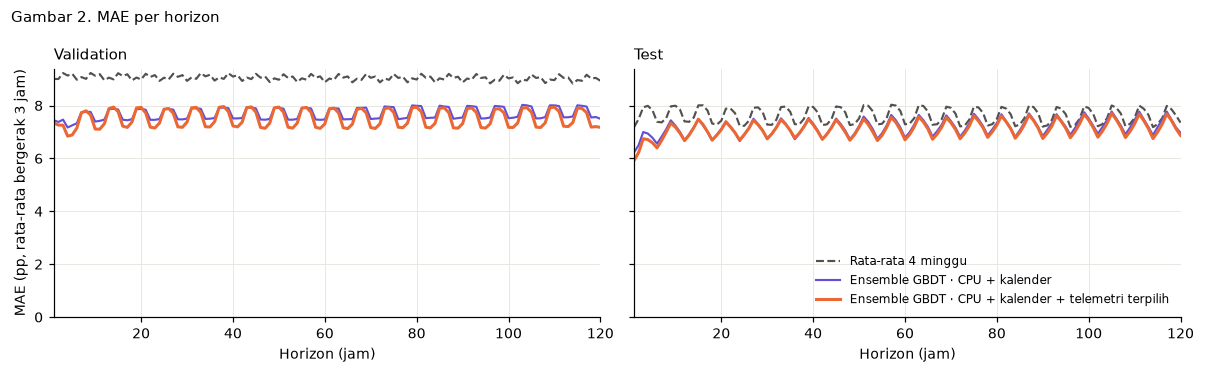

In [16]:
# Gambar 2: MAE per horizon
LINES = [("mean4w", COL["mean4w"], "--"), ("ens|cpu", COL["cpu"], "-"), ("ens|tele", COL["tele"], "-")]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, (ph, g) in zip(axs, ALL.groupby("phase", sort=False)):
    for c, col, ls in LINES:
        s = (g[c] - g.y).abs().groupby(g.h).mean().rolling(3, center=True, min_periods=1).mean()
        ax.plot(s.index, s.values, color=col, ls=ls, lw=2 if c == FINAL else 1.4, label=NAME[c])
    ax.set_title(FASE[ph]); ax.set_xlabel("Horizon (jam)"); ax.set_xlim(1, H)
axs[0].set_ylabel("MAE (pp, rata-rata bergerak 3 jam)"); axs[0].set_ylim(0, None); axs[1].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Gambar 2. MAE per horizon", x=.01, ha="left", fontsize=10); fig.tight_layout(); fig.savefig(f"{OUT_DIR}/figures/02_mae_per_horizon.png"); plt.show()

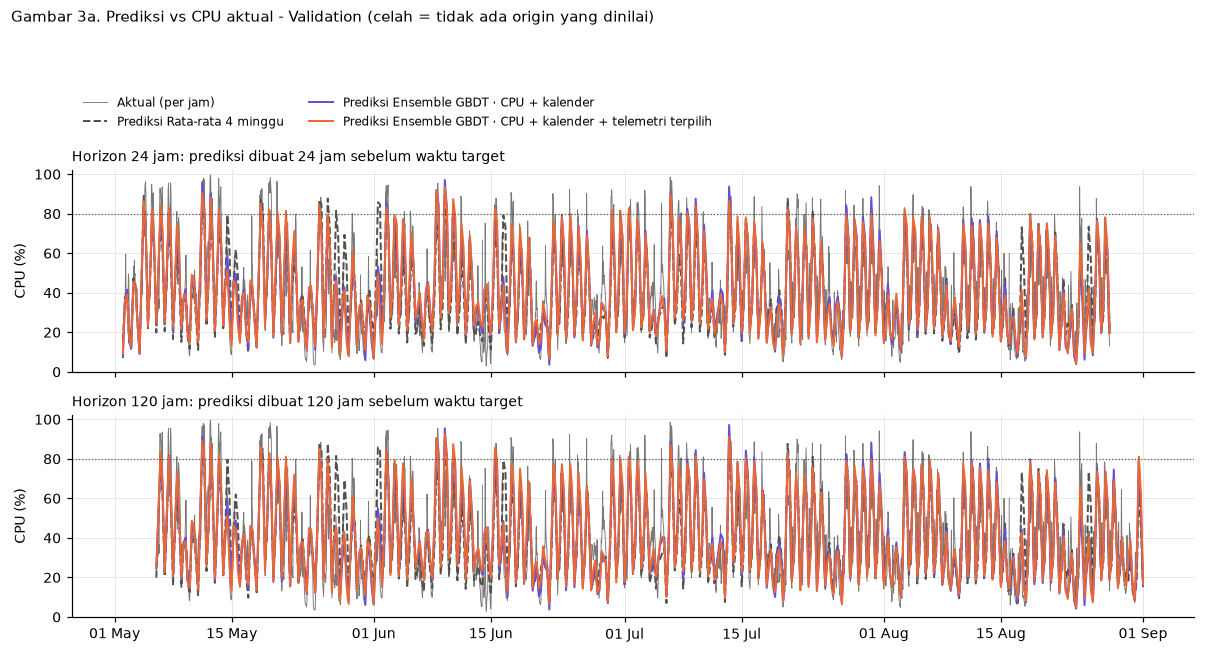

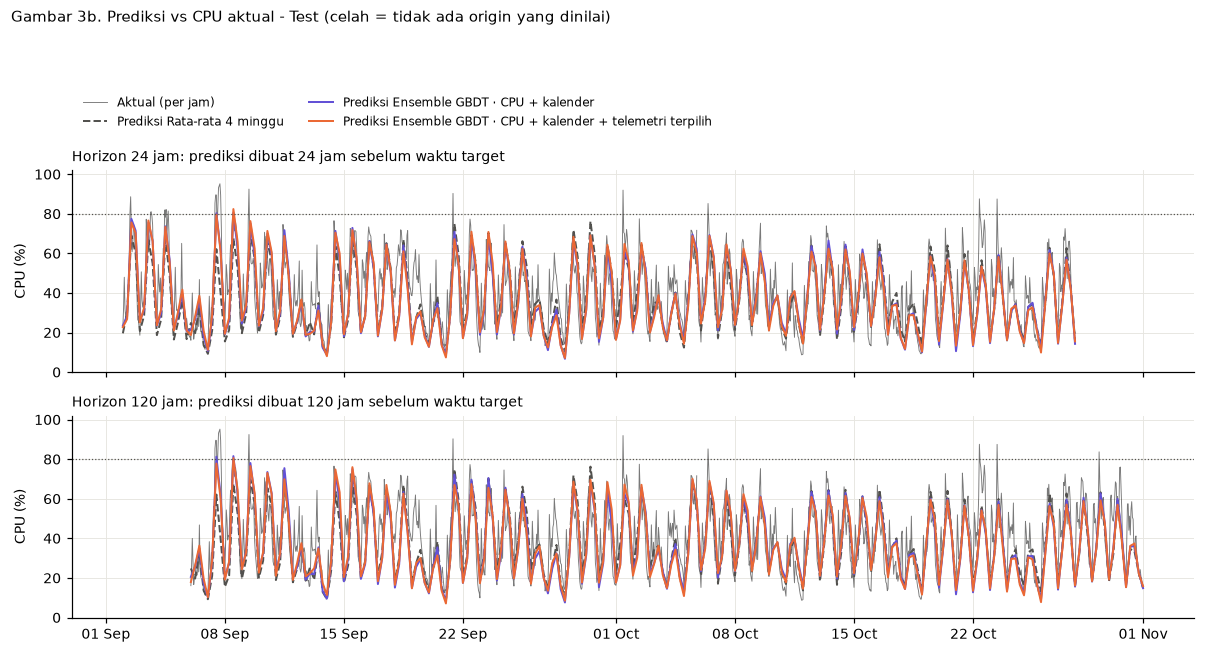

In [17]:
# Gambar 3: prediksi vs aktual sepanjang waktu (horizon 24 dan 120 jam)
for ph, g in ALL.groupby("phase", sort=False):
    fig, axs = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
    for ax, h in zip(axs, (24, 120)):
        gh = g[g.h == h].set_index("target_time").sort_index()[[c for c, _, _ in LINES]].asfreq(f"{SCORE_STRIDE}h")
        act = cpu_raw[(cpu_raw.index >= gh.index.min()) & (cpu_raw.index <= gh.index.max())]
        ax.plot(act.index, act.values, color=INK, lw=.6, alpha=.55, label="Aktual (per jam)")
        for c, col, ls in LINES: ax.plot(gh.index, gh[c], color=col, ls=ls, lw=1.3, label=f"Prediksi {NAME[c]}")
        ax.axhline(HIGH, color=INK2, ls=":", lw=.8); ax.set_ylim(0, 102); ax.set_ylabel("CPU (%)")
        ax.set_title(f"Horizon {h} jam: prediksi dibuat {h} jam sebelum waktu target", fontsize=9)
    axs[0].legend(frameon=False, ncol=2, fontsize=8, loc="upper left", bbox_to_anchor=(0, 1.42)); axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    fig.suptitle(f"Gambar 3{'ab'[ph == 'test']}. Prediksi vs CPU aktual - {FASE[ph]} (celah = tidak ada origin yang dinilai)", x=.01, ha="left", fontsize=10, y=1.05)
    fig.tight_layout(); fig.savefig(f"{OUT_DIR}/figures/03_prediksi_vs_aktual_{ph}.png", bbox_inches="tight"); plt.show()

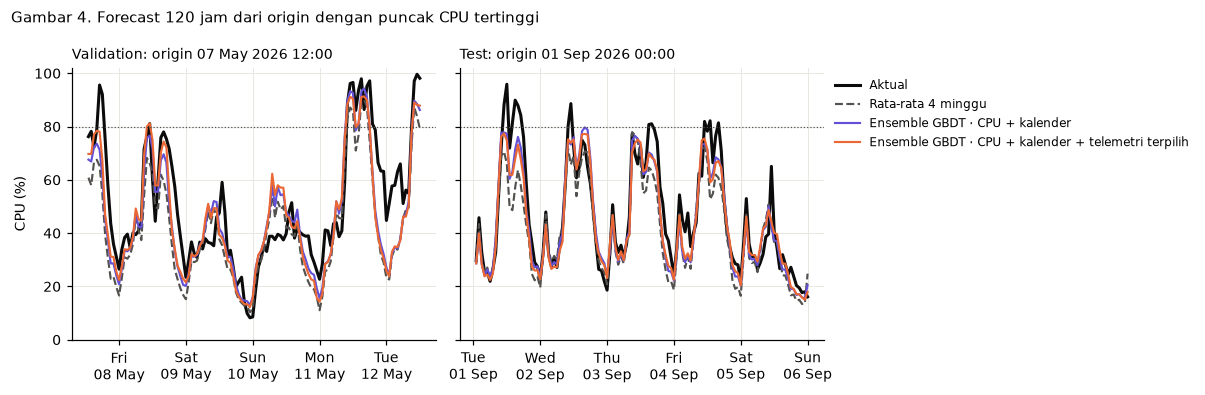

In [18]:
# Gambar 4: lintasan 120 jam dari origin sebelum puncak tertinggi tiap fase
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (ph, g) in zip(axs, ALL.groupby("phase", sort=False)):
    po = g.groupby("origin").y.max().idxmax(); gg = g[g.origin == po].sort_values("h"); tt = gg.target_time
    ax.plot(tt, gg.y, color=INK, lw=2, label="Aktual")
    for c, col, ls in LINES: ax.plot(tt, gg[c], color=col, ls=ls, lw=1.4, label=NAME[c])
    ax.axhline(HIGH, color=INK2, ls=":", lw=.8); ax.set_ylim(0, 102); ax.set_title(f"{FASE[ph]}: origin {po:%d %b %Y %H:%M}", fontsize=9)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%a\n%d %b"))
axs[0].set_ylabel("CPU (%)"); axs[1].legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.suptitle("Gambar 4. Forecast 120 jam dari origin dengan puncak CPU tertinggi", x=.01, ha="left", fontsize=10)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/figures/04_lintasan_puncak.png", bbox_inches="tight"); plt.show()

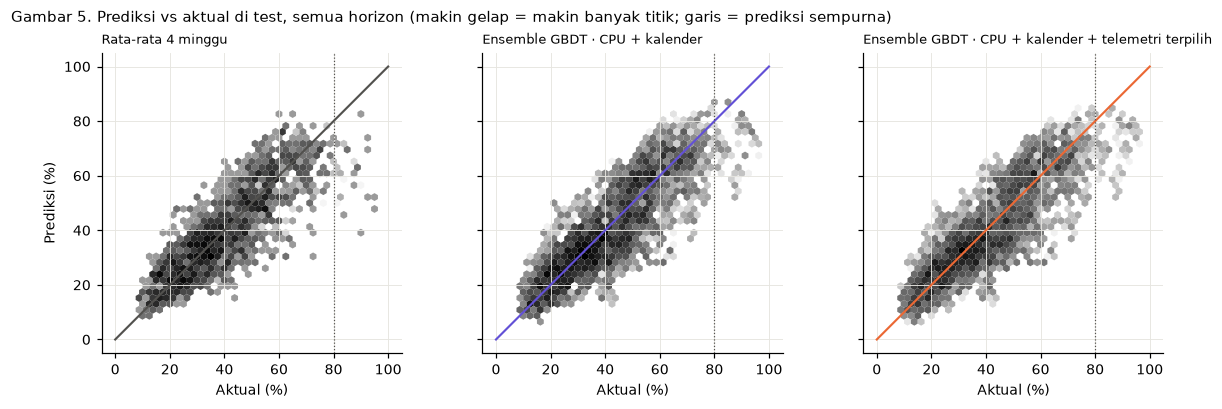

In [19]:
# Gambar 5: sebaran prediksi vs aktual di test (semua horizon)
g = ALL[ALL.phase == "test"]
fig, axs = plt.subplots(1, 3, figsize=(11, 3.6), sharex=True, sharey=True)
for ax, (c, col, _) in zip(axs, LINES):
    ax.hexbin(g.y, g[c], gridsize=40, extent=(0, 100, 0, 100), cmap="Greys", mincnt=1, bins="log", linewidths=0)
    ax.plot([0, 100], [0, 100], color=col, lw=1.4); ax.axvline(HIGH, color=INK2, ls=":", lw=.8)
    ax.set_title(NAME[c], fontsize=8.5); ax.set_xlabel("Aktual (%)"); ax.set_aspect("equal")
axs[0].set_ylabel("Prediksi (%)")
fig.suptitle("Gambar 5. Prediksi vs aktual di test, semua horizon (makin gelap = makin banyak titik; garis = prediksi sempurna)", x=.01, ha="left", fontsize=10)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/figures/05_sebaran_test.png", bbox_inches="tight"); plt.show()

### 8.3 Pembanding linear: Ridge musiman multivariat (tujuan 1)

Ridge adalah model terbaik di pipeline awal, sehingga perlu dinilai ulang dengan protokol yang sama dengan model final. Ridge memakai fitur yang sama ditambah dummy jam dan hari target (pola musiman harian dan mingguan; Hyndman & Athanasopoulos, 2021, §7.4), dan penalti L2 (James dkk., 2021, §6.2).

- Grid per set fitur: target langsung atau residual terhadap rata-rata 4 minggu × alpha ∈ {10, 100, 1000}. Konfigurasi terbaik per set fitur = MAE validation terendah.
- Ridge **di luar seleksi beku**: tidak bisa menjadi model final dan tidak mengubah pra-registrasi. Hasil test-nya eksploratori, sama dengan model lain.
- Uji beda memakai Diebold–Mariano fixed-m (Coroneo & Iacone, 2020).

In [20]:
RIDGE_GRID = [{"kind": "ridge", "fs": fs, "target": target, "hl": None, "alpha": a} for fs in FS for target in ("raw", "resid") for a in RIDGE_ALPHAS]
(RV, LOGRV), how_rv = run_phase("validation", RIDGE_GRID); RV = apply_fallback(RV, RIDGE_GRID)
RBEST = {fs: min([s for s in RIDGE_GRID if s["fs"] == fs], key=lambda s: mae(RV, spec_key(s))) for fs in FS}
RT_SPECS = list({spec_key(s): s for s in list(RBEST.values()) + [dict(RBEST["tele"], fs="cpu")]}.values())     # kembaran CPU untuk fallback C3
(RT, LOGRT), how_rt = run_phase("test", RT_SPECS); RT = apply_fallback(RT, RT_SPECS)
print(f"Ridge validation: {how_rv} | test: {how_rt}")
RK = {fs: spec_key(s) for fs, s in RBEST.items()}
for fs, k in RK.items(): NAME[k] = f"Ridge · {FS[fs]}"
AR = ALL.merge(pd.concat([RV, RT], ignore_index=True)[["origin", "target_time"] + list(RK.values())], on=["origin", "target_time"], how="left", validate="one_to_one")
assert AR[list(RK.values())].notna().all().all(), "prediksi Ridge tidak lengkap"
show(pd.DataFrame([{"Set fitur": FS[fs], "Konfigurasi terpilih (validation)": spec_label(s), "MAE validation": mae(RV, spec_key(s))} for fs, s in RBEST.items()]),
     {"MAE validation": "{:.3f}"}, "Tabel 12f. Ridge terbaik per set fitur (dipilih di validation)")
T12G = pd.DataFrame([{"Fase": FASE[ph], "Model": NAME[c], "Final": "✓" if c == FINAL else "", **met(g, c)}
                     for ph, g in AR.groupby("phase", sort=False) for c in ["snaive", "mean4w"] + list(RK.values()) + [FINAL]])
T12G.to_csv(f"{OUT_DIR}/metrik_ridge.csv", index=False); show(T12G, F, "Tabel 12g. Ridge musiman multivariat vs model final dan pembanding musiman")
rows = []
for ph, g in AR.groupby("phase", sort=False):
    for a, b in [(FINAL, RK[fs]) for fs in FS] + [(RK[fs], "mean4w") for fs in FS]:
        r = compare(g, a, b); rows.append({"Fase": FASE[ph], "Model A": NAME[a], "Dibanding (B)": NAME[b], "Selisih MAE (A − B)": r["selisih"],
                                           "CI 95% bawah": r["ci_lo"], "CI 95% atas": r["ci_hi"], "p": r["p"], "T origin": r["T"], "Kesimpulan": r["Kesimpulan"]})
DMR = pd.DataFrame(rows); DMR.to_csv(f"{OUT_DIR}/uji_dm_ridge.csv", index=False)
show(DMR, {"Selisih MAE (A − B)": "{:+.3f}", "CI 95% bawah": "{:+.3f}", "CI 95% atas": "{:+.3f}", "p": "{:.3f}", "T origin": "{:d}"},
     "Tabel 12h. Uji Diebold–Mariano fixed-m: model final vs Ridge, dan Ridge vs rata-rata 4 minggu (negatif = model A lebih akurat)")

Ridge validation: dilatih 3.5 menit | test: dilatih 0.4 menit


Set fitur,Konfigurasi terpilih (validation),MAE validation
CPU + kalender,Ridge · CPU + kalender · target residual · alpha 1000,8.672
CPU + kalender + telemetri terpilih,Ridge · CPU + kalender + telemetri terpilih · target residual · alpha 1000,8.710


Fase,Model,Final,MAE,MAE relatif,RMSE,Bias,MAE puncak,Bias puncak
Validation,Naif musiman mingguan,,11.21,1.239,15.86,+0.29,15.53,-13.14
Validation,Rata-rata 4 minggu,,9.05,1.000,12.81,+0.92,14.16,-13.41
Validation,Ridge · CPU + kalender,,8.67,0.959,11.45,+3.48,11.09,-10.50
Validation,Ridge · CPU + kalender + telemetri terpilih,,8.71,0.963,11.48,+2.31,12.32,-11.75
Validation,Ensemble GBDT · CPU + kalender + telemetri terpilih,✓,7.51,0.831,9.82,+1.35,9.73,-8.85
Test,Naif musiman mingguan,,8.87,1.165,11.81,-0.26,25.34,-25.10
Test,Rata-rata 4 minggu,,7.62,1.000,9.94,-0.58,26.44,-26.44
Test,Ridge · CPU + kalender,,7.63,1.002,9.60,-0.24,16.90,-16.89
Test,Ridge · CPU + kalender + telemetri terpilih,,7.94,1.043,9.99,+0.05,15.39,-15.34
Test,Ensemble GBDT · CPU + kalender + telemetri terpilih,✓,7.11,0.933,9.22,-1.07,16.31,-16.31


Fase,Model A,Dibanding (B),Selisih MAE (A − B),CI 95% bawah,CI 95% atas,p,T origin,Kesimpulan
Validation,Ensemble GBDT · CPU + kalender + telemetri terpilih,Ridge · CPU + kalender,-1.159,-1.706,-0.612,0.000,473,lebih baik
Validation,Ensemble GBDT · CPU + kalender + telemetri terpilih,Ridge · CPU + kalender + telemetri terpilih,-1.198,-1.900,-0.496,0.003,473,lebih baik
Validation,Ridge · CPU + kalender,Rata-rata 4 minggu,-0.373,-1.375,+0.629,0.438,473,tidak berbeda nyata
Validation,Ridge · CPU + kalender + telemetri terpilih,Rata-rata 4 minggu,-0.334,-1.562,+0.895,0.569,473,tidak berbeda nyata
Test,Ensemble GBDT · CPU + kalender + telemetri terpilih,Ridge · CPU + kalender,-0.524,-0.980,-0.067,0.028,225,lebih baik
Test,Ensemble GBDT · CPU + kalender + telemetri terpilih,Ridge · CPU + kalender + telemetri terpilih,-0.834,-1.382,-0.286,0.006,225,lebih baik
Test,Ridge · CPU + kalender,Rata-rata 4 minggu,+0.015,-0.697,+0.727,0.964,225,tidak berbeda nyata
Test,Ridge · CPU + kalender + telemetri terpilih,Rata-rata 4 minggu,+0.325,-0.544,+1.194,0.431,225,tidak berbeda nyata


### 8.4 Weighted loss untuk beban tinggi (tujuan 2)

Prediksi yang meminimalkan MAE adalah median bersyarat, sehingga jam beban tinggi yang langka cenderung diprediksi terlalu rendah (Kolassa, 2020); bias puncak di Tabel 10 menunjukkan hal itu. Cara baku untuk memberi perhatian lebih pada nilai ekstrem yang langka dalam regresi adalah **memberi bobot lebih besar pada sampel ekstrem di fungsi loss** (Ribeiro & Moniz, 2020).

- Bobot sampel training = (bobot waktu model final) × (1 + λ · 1[CPU aktual ≥ 80 %]), dengan λ ∈ {1, 3, 9}. λ = 0 adalah model final apa adanya.
- Konfigurasi lain (keluarga, set fitur, target, half-life) **sama dengan seleksi beku**; yang berubah hanya λ. Model yang dinilai adalah ensemble tiga boosting, seperti model final.
- Yang diukur adalah **trade-off**: berapa MAE puncak (jam CPU aktual ≥ 80 %, metrik bersyarat) turun dibanding berapa MAE keseluruhan naik. Selisih MAE keseluruhan diuji dengan DM fixed-m; selisih MAE puncak diuji dengan DM pada origin yang punya jam puncak, bila jumlahnya ≥ 20.
- Bagian ini **analisis**, bukan seleksi: λ tidak dipilih ulang dan model final tidak berubah. Pemilihan λ untuk operasi bergantung pada seberapa besar kenaikan MAE keseluruhan yang masih bisa diterima pengelola server.

bobot puncak λ = 1 · validation: dilatih 2.6 menit


bobot puncak λ = 1 · test: dilatih 1.8 menit


bobot puncak λ = 3 · validation: dilatih 3.0 menit


bobot puncak λ = 3 · test: dilatih 2.1 menit


bobot puncak λ = 9 · validation: dilatih 2.8 menit


bobot puncak λ = 9 · test: dilatih 2.0 menit


Fase,λ,MAE keseluruhan,Perubahan MAE keseluruhan (%),CI 95% selisih keseluruhan,MAE puncak,Perubahan MAE puncak (%),CI 95% selisih puncak,Bias puncak,MAE non-puncak,Baris puncak
Validation,0,7.514,+0.0,–,9.73,+0.0,–,-8.85,7.356,3788
Validation,1,7.758,+3.2,[+0.10; +0.39],8.70,-10.5,[-2.21; -0.88] (T = 446),-7.53,7.691,3788
Validation,3,8.078,+7.5,[+0.30; +0.83],7.20,-25.9,[-4.63; -2.28] (T = 446),-5.54,8.141,3788
Validation,9,8.632,+14.9,[+0.74; +1.50],6.49,-33.3,[-6.27; -2.75] (T = 446),-4.47,8.786,3788
Test,0,7.106,+0.0,–,16.31,+0.0,–,-16.31,6.973,385
Test,1,7.184,+1.1,[-0.06; +0.21],14.35,-12.0,[-2.58; -0.64] (T = 129),-14.22,7.081,385
Test,3,7.540,+6.1,[+0.12; +0.75],12.74,-21.9,[-4.67; -2.13] (T = 129),-12.44,7.465,385
Test,9,8.436,+18.7,[+0.72; +1.94],9.44,-42.1,[-9.33; -5.49] (T = 129),-8.53,8.422,385


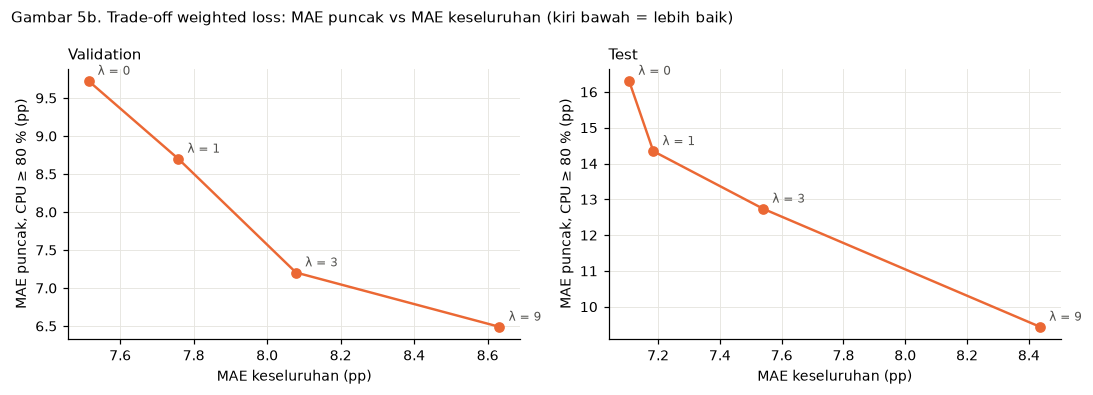

In [21]:
fs_w = FINAL.split("|")[1] if FINAL.startswith("ens|") else next(s["fs"] for s in BEST.values() if spec_key(s) == FINAL)
BASE_W = [BEST[(k, fs_w)] for k in KINDS]; COL_W = {0: f"ens|{fs_w}"}
W = ALL[["origin", "target_time", "h", "y", "phase", COL_W[0]]].copy()
for lam in PEAK_LAMBDAS[1:]:
    sp = [dict(s, peak=lam) for s in BASE_W]
    if fs_w == "tele": sp += [dict(s, fs="cpu", peak=lam) for s in BASE_W if FALLBACK.reindex(ELIG).any()]   # kembaran untuk fallback C3
    parts = []
    for ph in SPLIT:
        (P_, _), how_ = run_phase(ph, sp); P_ = apply_fallback(P_, sp); print(f"bobot puncak λ = {lam:g} · {ph}: {how_}")
        parts.append(P_[["origin", "target_time"]].assign(**{f"ensw|{lam:g}": P_[[spec_key(s) for s in sp[:len(KINDS)]]].mean(axis=1).to_numpy()}))
    COL_W[lam] = f"ensw|{lam:g}"; W = W.merge(pd.concat(parts, ignore_index=True), on=["origin", "target_time"], how="left", validate="one_to_one")
assert W[list(COL_W.values())].notna().all().all(), "prediksi weighted loss tidak lengkap"

def dm_puncak(g, a, b):
    """DM pada selisih galat absolut di jam puncak, dirata-rata per origin yang punya jam puncak."""
    pk = g[g.y >= HIGH]; d = ((pk[a] - pk.y).abs() - (pk[b] - pk.y).abs()).groupby(pk.origin).mean().sort_index()
    return dm_fixed_m(d.to_numpy()) if len(d) >= N_DM_MIN else {"T": len(d), "ci_lo": np.nan, "ci_hi": np.nan}
rows = []
for ph, g in W.groupby("phase", sort=False):
    pk = g.y >= HIGH; base = g[COL_W[0]]
    m0, p0 = (base - g.y).abs().mean(), (base - g.y)[pk].abs().mean()
    for lam, c in COL_W.items():
        e = g[c] - g.y; r = compare(g, c, COL_W[0]) if lam else None; rp = dm_puncak(g, c, COL_W[0]) if lam else None
        rows.append({"Fase": FASE[ph], "λ": lam, "MAE keseluruhan": e.abs().mean(), "Perubahan MAE keseluruhan (%)": 100 * (e.abs().mean() / m0 - 1),
                     "CI 95% selisih keseluruhan": f"[{r['ci_lo']:+.2f}; {r['ci_hi']:+.2f}]" if lam else "–",
                     "MAE puncak": e[pk].abs().mean(), "Perubahan MAE puncak (%)": 100 * (e[pk].abs().mean() / p0 - 1),
                     "CI 95% selisih puncak": (f"[{rp['ci_lo']:+.2f}; {rp['ci_hi']:+.2f}] (T = {rp['T']})" if np.isfinite(rp["ci_lo"]) else f"terlalu sedikit (T = {rp['T']})") if lam else "–",
                     "Bias puncak": e[pk].mean(), "MAE non-puncak": e[~pk].abs().mean(), "Baris puncak": int(pk.sum())})
T12I = pd.DataFrame(rows); T12I.to_csv(f"{OUT_DIR}/weighted_loss_puncak.csv", index=False)
show(T12I, {"λ": "{:g}", "MAE keseluruhan": "{:.3f}", "Perubahan MAE keseluruhan (%)": "{:+.1f}", "MAE puncak": "{:.2f}", "Perubahan MAE puncak (%)": "{:+.1f}",
            "Bias puncak": "{:+.2f}", "MAE non-puncak": "{:.3f}", "Baris puncak": "{:d}"},
     f"Tabel 12i. Weighted loss puncak pada {NAME[COL_W[0]]}: trade-off MAE puncak vs MAE keseluruhan (λ = 0 = model final; CI = DM fixed-m terhadap λ = 0)")

# Gambar 5b: kurva trade-off
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (ph, g) in zip(axs, T12I.groupby("Fase", sort=False)):
    ax.plot(g["MAE keseluruhan"], g["MAE puncak"], color=COL["tele"], marker="o", lw=1.6)
    for _, r in g.iterrows(): ax.annotate(f"λ = {r['λ']:g}", (r["MAE keseluruhan"], r["MAE puncak"]), xytext=(6, 4), textcoords="offset points", fontsize=8, color=INK2)
    ax.set_title(ph); ax.set_xlabel("MAE keseluruhan (pp)"); ax.set_ylabel("MAE puncak, CPU ≥ 80 % (pp)")
fig.suptitle("Gambar 5b. Trade-off weighted loss: MAE puncak vs MAE keseluruhan (kiri bawah = lebih baik)", x=.01, ha="left", fontsize=10)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/figures/05b_tradeoff_weighted_loss.png", bbox_inches="tight"); plt.show()

## 9. Prediksi probabilistik: kuantil dan interval 120 jam

Prediksi titik yang meminimalkan MAE adalah median, sehingga lonjakan langka cenderung diprediksi terlalu rendah (Kolassa, 2020). Itulah yang terlihat di Tabel 10.
Untuk perencanaan kapasitas, yang dibutuhkan adalah **rentang kemungkinan** beban, bukan hanya satu angka. Prediksi beban server yang menyertakan ketidakpastian memang terbukti lebih berguna untuk metrik layanan (Rossi dkk., 2025).

**Tiga metode yang dibandingkan.** Semuanya memprediksi 7 kuantil: 0,05, 0,10, 0,25, 0,50, 0,75, 0,90, dan 0,95.

| Metode | Isi | Dasar |
|---|---|---|
| **LightGBM kuantil** | LightGBM dengan loss kuantil, satu model per kuantil. Fitur dan konfigurasinya sama dengan LightGBM terbaik model final (seleksi beku). | Januschowski dkk. (2022); Makridakis dkk. (2022b) |
| **LightGBM kuantil + kalibrasi konformal sekuensial** | Setiap kuantil digeser sebesar kuantil empiris dari (aktual − prediksi kuantil) pada galat yang **sudah matang** dalam 28 hari terakhir, per pita horizon. | Xu & Xie (2023) |
| **Prediksi titik model final + kuantil galat terkini (EnbPI)** | Kuantil = prediksi titik model final + kuantil empiris galat titik yang sudah matang dalam 28 hari terakhir, per pita horizon. | Xu & Xie (2023) |

**Galat yang sudah matang** adalah galat dari origin sebelumnya yang waktu targetnya sudah lewat pada saat origin *t*. Artinya hanya memakai informasi yang benar-benar tersedia saat prediksi dibuat.
Riwayat galat awal diambil dari bulan **April 2026** (model dilatih ulang 1 April). Bulan ini hanya dipakai sebagai riwayat kalibrasi dan tidak dinilai.
Kuantil yang bersilangan diurutkan ulang per baris, supaya kuantil yang lebih tinggi tidak pernah lebih kecil.

**Evaluasi** (Hyndman & Athanasopoulos, 2021, §5.9; Makridakis dkk., 2022b):
- **Skor kuantil** rata-rata atas 7 kuantil. Ini *proper scoring rule*: makin kecil makin baik, dan pada kuantil 0,5 sama dengan galat absolut.
- **Cakupan** interval 80% (kuantil 0,10–0,90) dan 90% (kuantil 0,05–0,95). Idealnya mendekati nilai nominalnya.
- **Lebar** interval dan **skor Winkler**, yang memberi penalti pada interval yang lebar maupun yang meleset.

**Aturan seleksi** (validation saja): metode dengan skor kuantil rata-rata terendah. Seleksi dibekukan sebelum kuantil test dihitung.

In [22]:
fs_final = FINAL.split("|")[1] if FINAL.startswith("ens|") else next(s["fs"] for s in BEST.values() if spec_key(s) == FINAL)
POINT_SPECS = [BEST[(k, fs_final)] for k in ("hgb", "lgbm", "xgb")] if FINAL.startswith("ens|") else [s for s in BEST.values() if spec_key(s) == FINAL]
QBASE = BEST[("lgbm", fs_final)]
QSPECS = [dict(QBASE, kind="lgbm_q", q=q) for q in QLEVELS]
QC = {q: spec_key(s) for q, s in zip(QLEVELS, QSPECS)}
BANDS, BAND_LBL = [0, 6, 24, 72, H], ["1–6 jam", "7–24 jam", "25–72 jam", "73–120 jam"]
PNAME = {"m1": "LightGBM kuantil", "m2": "LightGBM kuantil + kalibrasi konformal sekuensial", "m3": "Prediksi titik model final + kuantil galat terkini (EnbPI)"}
PCOL = {"m1": "#6250d6", "m2": "#eb6834", "m3": "#2a78d6"}
TAU = np.array(QLEVELS); I80 = (QLEVELS.index(0.10), QLEVELS.index(0.90)); I90 = (QLEVELS.index(0.05), QLEVELS.index(0.95))

def stream_part(point_df, q_df, phase):
    s = point_df[["origin", "target_time", "h", "y"]].copy()
    s["point"] = point_df[[spec_key(x) for x in POINT_SPECS]].mean(axis=1).to_numpy()
    s = s.merge(q_df[["origin", "h"] + list(QC.values())], on=["origin", "h"], how="left", validate="one_to_one")
    s["phase"] = phase; s["band_i"] = pd.cut(s.h, BANDS, labels=False); return s

def window_shifts(stream, eval_origins):
    """Untuk tiap origin t dan pita horizon: kuantil empiris galat yang sudah matang (target_time <= t) dari origin dalam 28 hari terakhir."""
    st = stream[stream.y.notna()]
    o, tt, bi = st.origin.to_numpy(), st.target_time.to_numpy(), st.band_i.to_numpy()
    r_pt = (st.y - st.point).to_numpy(); r_q = {q: (st.y - st[QC[q]]).to_numpy() for q in QLEVELS}
    W = np.timedelta64(WINDOW_DAYS, "D"); rows = []
    for t in np.sort(np.asarray(pd.DatetimeIndex(eval_origins), dtype="datetime64[ns]")):
        m0 = (o >= t - W) & (tt <= t)
        for b in range(len(BAND_LBL)):
            m = m0 & (bi == b); n = int(m.sum()); r = {"origin": pd.Timestamp(t), "band_i": b, "n_kal": n}
            for q in QLEVELS:
                r[f"c2_{q}"] = np.quantile(r_q[q][m], q) if n >= MIN_CAL else np.nan
                r[f"c3_{q}"] = np.quantile(r_pt[m], q) if n >= MIN_CAL else np.nan
            rows.append(r)
    return pd.DataFrame(rows)

def build_methods(stream, phase, shifts):
    d = stream[stream.phase == phase].merge(shifts, on=["origin", "band_i"], how="left")
    Q1 = np.column_stack([d[QC[q]].to_numpy() for q in QLEVELS])
    C2 = np.column_stack([d[f"c2_{q}"].to_numpy() for q in QLEVELS]); C3 = np.column_stack([d[f"c3_{q}"].to_numpy() for q in QLEVELS])
    M = {"m1": np.sort(Q1, axis=1), "m2": np.sort(Q1 + C2, axis=1), "m3": d.point.to_numpy()[:, None] + C3}
    ok = np.isfinite(M["m2"]).all(axis=1) & np.isfinite(M["m3"]).all(axis=1)       # baris dengan riwayat kalibrasi cukup
    return d[ok].reset_index(drop=True), {k: np.clip(v[ok], 0, 100) for k, v in M.items()}, int((~ok).sum())

def prob_metrics(d, Q):
    y = d.y.to_numpy(); e = y[:, None] - Q
    qs = 2 * np.maximum(TAU * e, (TAU - 1) * e)                                     # skor kuantil (Hyndman & Athanasopoulos, 2021, §5.9)
    def wink(i, alpha):
        l, u = Q[:, i[0]], Q[:, i[1]]; return ((u - l) + (2 / alpha) * np.clip(l - y, 0, None) + (2 / alpha) * np.clip(y - u, 0, None)).mean()
    pk = y >= HIGH
    return {"Skor kuantil": qs.mean(), "Cakupan 80% (%)": 100 * np.mean((y >= Q[:, I80[0]]) & (y <= Q[:, I80[1]])), "Lebar 80%": np.mean(Q[:, I80[1]] - Q[:, I80[0]]),
            "Winkler 80%": wink(I80, .2), "Cakupan 90% (%)": 100 * np.mean((y >= Q[:, I90[0]]) & (y <= Q[:, I90[1]])), "Lebar 90%": np.mean(Q[:, I90[1]] - Q[:, I90[0]]),
            "Winkler 90%": wink(I90, .1), "Puncak di bawah kuantil 0,95 (%)": 100 * np.mean(y[pk] <= Q[pk, QLEVELS.index(0.95)]) if pk.any() else np.nan}

(PK, LOGK), how_k = run_phase("kalibrasi", POINT_SPECS + QSPECS)
(PQV, LOGQV), how_qv = run_phase("validation", QSPECS)
for p_ in (PK, PQV): assert not FALLBACK.reindex(p_.origin.unique()).any(), "ada origin fallback: kuantil telemetri tidak terdefinisi"
STREAM = pd.concat([stream_part(PK, PK, "kalibrasi"), stream_part(PV, PQV, "validation")], ignore_index=True)
SH_V = window_shifts(STREAM, PV.origin.unique()); DV, MV_, miss_v = build_methods(STREAM, "validation", SH_V)
val_prob = {k: prob_metrics(DV, MV_[k]) for k in PNAME}
PROB_FINAL = min(PNAME, key=lambda k: val_prob[k]["Skor kuantil"])
PSEL_PATH, PFLAG = f"{OUT_DIR}/seleksi_probabilistik_beku.json", f"{OUT_DIR}/test_probabilistik_sudah_dijalankan.flag"
psel = {"dibekukan": time.strftime("%Y-%m-%d %H:%M:%S"), "aturan": "skor kuantil rata-rata validation terendah", "metode_terpilih": PNAME[PROB_FINAL], "kunci": PROB_FINAL,
        "skor_validation": {PNAME[k]: v["Skor kuantil"] for k, v in val_prob.items()}, "kuantil": QLEVELS, "jendela_hari": WINDOW_DAYS, "min_galat": MIN_CAL,
        "pita_horizon": BANDS, "konfigurasi_lightgbm_kuantil": QBASE, "model_titik": [spec_label(s) for s in POINT_SPECS], "seleksi_titik_sha256": open(SEL_PATH + ".sha256").read().strip()}
if os.path.exists(PSEL_PATH):
    old = json.load(open(PSEL_PATH)); assert sha_file(PSEL_PATH) == open(PSEL_PATH + ".sha256").read().strip(), "seleksi probabilistik berubah setelah dibekukan!"
    assert old["kunci"] == PROB_FINAL, "seleksi probabilistik berbeda dari yang dibekukan"; psel = old
else:
    assert not os.path.exists(PFLAG), "test probabilistik sudah dijalankan; seleksi tidak boleh dibuat ulang"
    json.dump(psel, open(PSEL_PATH, "w"), indent=2, default=str); open(PSEL_PATH + ".sha256", "w").write(sha_file(PSEL_PATH))
print(f"kalibrasi April: {how_k} | kuantil validation: {how_qv} | baris tanpa riwayat kalibrasi cukup: {miss_v}")
display(Markdown(f"**Metode probabilistik terpilih (validation): {PNAME[PROB_FINAL]}** · dibekukan {psel['dibekukan']}, sha256 {open(PSEL_PATH + '.sha256').read()[:12]}…"))

kalibrasi April: dilatih 2.3 menit | kuantil validation: dilatih 9.6 menit | baris tanpa riwayat kalibrasi cukup: 0


**Metode probabilistik terpilih (validation): Prediksi titik model final + kuantil galat terkini (EnbPI)** · dibekukan 2026-11-10 22:41:53, sha256 3eeb8a74e361…

In [23]:
# Test probabilistik: dijalankan setelah seleksi dibekukan
(PQT, LOGQT), how_qt = run_phase("test", QSPECS)
assert not FALLBACK.reindex(PQT.origin.unique()).any(), "ada origin fallback di test"
if not os.path.exists(PFLAG): open(PFLAG, "w").write(f"test probabilistik dijalankan {time.strftime('%Y-%m-%d %H:%M:%S')} dengan seleksi sha256 {open(PSEL_PATH + '.sha256').read()[:12]}")
STREAM = pd.concat([STREAM, stream_part(PT, PQT, "test")], ignore_index=True)
SH_T = window_shifts(STREAM, PT.origin.unique()); DT, MT_, miss_t = build_methods(STREAM, "test", SH_T)
print(f"kuantil test: {how_qt} | baris tanpa riwayat kalibrasi cukup: {miss_t} | {open(PFLAG).read()}")
PROB = {"validation": (DV, MV_), "test": (DT, MT_)}
rows = [{"Fase": FASE[ph], "Metode": PNAME[k], "Terpilih": "✓" if k == PROB_FINAL else "", **prob_metrics(d, M[k])} for ph, (d, M) in PROB.items() for k in PNAME]
T14 = pd.DataFrame(rows); T14.to_csv(f"{OUT_DIR}/metrik_probabilistik.csv", index=False)
show(T14, {"Skor kuantil": "{:.3f}", "Cakupan 80% (%)": "{:.1f}", "Lebar 80%": "{:.1f}", "Winkler 80%": "{:.2f}", "Cakupan 90% (%)": "{:.1f}", "Lebar 90%": "{:.1f}",
           "Winkler 90%": "{:.2f}", "Puncak di bawah kuantil 0,95 (%)": "{:.1f}"},
     "Tabel 13. Prediksi probabilistik (cakupan ideal: 80% dan 90%; skor kuantil dan Winkler: makin kecil makin baik)")
qd = pd.concat([pd.DataFrame({"Fase": FASE[ph], "Kuantil nominal": QLEVELS, **{PNAME[k]: 100 * (d.y.to_numpy()[:, None] <= M[k]).mean(axis=0) for k in PNAME}})
                for ph, (d, M) in PROB.items()])
show(qd, {"Kuantil nominal": "{:.2f}"} | {PNAME[k]: "{:.1f}" for k in PNAME}, "Tabel 14. Kalibrasi per kuantil: % aktual di bawah kuantil (ideal = kuantil nominal × 100)")
out = pd.concat([d[["origin", "target_time", "h", "y", "point"]].assign(phase=ph, **{f"q{q}": M[PROB_FINAL][:, j] for j, q in enumerate(QLEVELS)}) for ph, (d, M) in PROB.items()])
out.to_csv(f"{OUT_DIR}/prediksi_kuantil.csv.gz", index=False, float_format="%.3f")

kuantil test: dilatih 5.4 menit | baris tanpa riwayat kalibrasi cukup: 0 | test probabilistik dijalankan 2026-11-10 22:47:29 dengan seleksi sha256 3eeb8a74e361


Fase,Metode,Terpilih,Skor kuantil,Cakupan 80% (%),Lebar 80%,Winkler 80%,Cakupan 90% (%),Lebar 90%,Winkler 90%,"Puncak di bawah kuantil 0,95 (%)"
Validation,LightGBM kuantil,,4.662,65.1,18.8,37.69,78.8,26.1,46.99,54.3
Validation,LightGBM kuantil + kalibrasi konformal sekuensial,,4.637,76.7,24.1,36.53,87.6,32.2,44.27,70.0
Validation,Prediksi titik model final + kuantil galat terkini (EnbPI),✓,4.542,77.6,22.5,35.91,88.1,30.2,44.24,74.6
Test,LightGBM kuantil,,4.146,68.0,18.4,32.94,83.7,25.7,39.98,42.3
Test,LightGBM kuantil + kalibrasi konformal sekuensial,,4.242,77.2,22.3,33.54,87.7,30.0,41.11,48.1
Test,Prediksi titik model final + kuantil galat terkini (EnbPI),✓,4.327,77.6,22.6,33.91,88.7,30.1,41.62,43.4


Fase,Kuantil nominal,LightGBM kuantil,LightGBM kuantil + kalibrasi konformal sekuensial,Prediksi titik model final + kuantil galat terkini (EnbPI)
Validation,0.05,13.4,6.9,6.0
Validation,0.10,21.7,12.0,10.7
Validation,0.25,36.7,26.2,26.1
Validation,0.50,56.1,48.7,48.5
Validation,0.75,73.4,72.8,72.5
Validation,0.90,86.8,88.7,88.3
Validation,0.95,92.2,94.5,94.1
Test,0.05,8.0,5.3,4.8
Test,0.10,15.9,10.3,9.2
Test,0.25,28.9,24.2,24.2


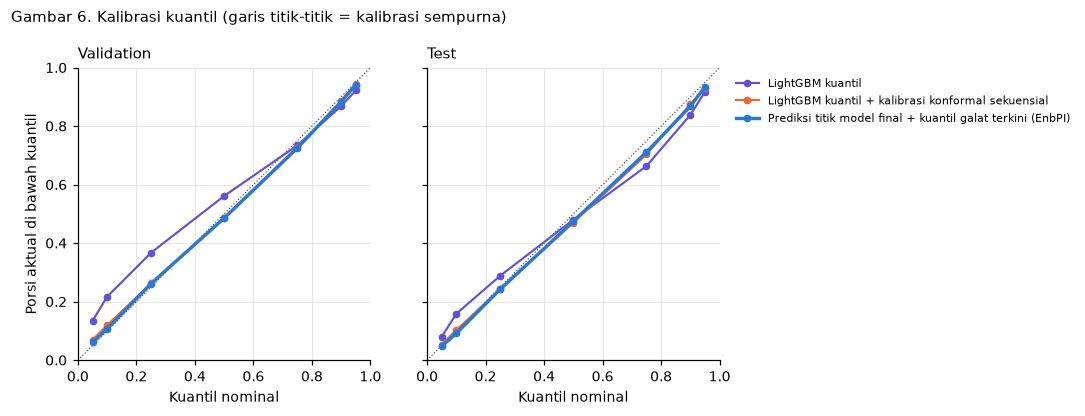

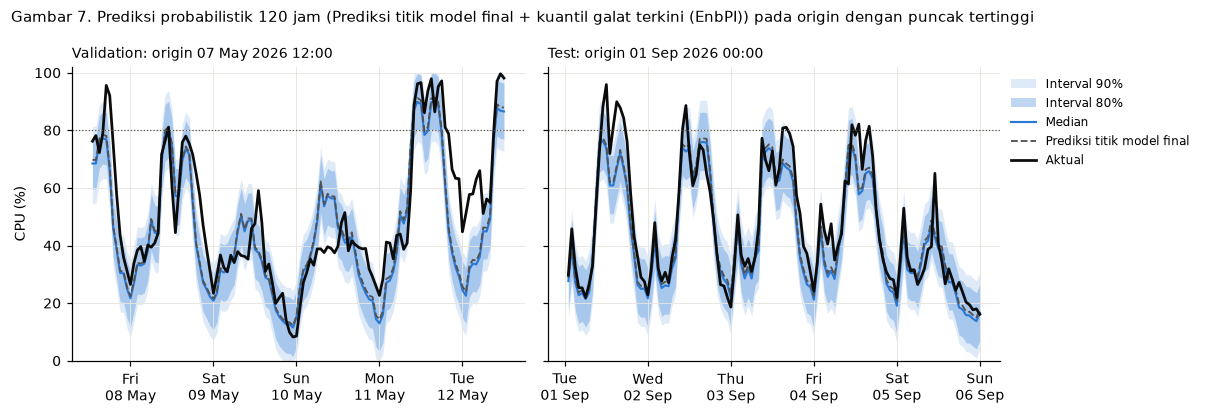

In [24]:
# Gambar 6: kalibrasi kuantil (nominal vs empiris) dan Gambar 7: fan chart 120 jam pada origin puncak
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, (ph, (d, M)) in zip(axs, PROB.items()):
    ax.plot([0, 1], [0, 1], color=INK2, lw=.8, ls=":")
    for k in PNAME: ax.plot(TAU, (d.y.to_numpy()[:, None] <= M[k]).mean(axis=0), marker="o", ms=4, lw=1.4 if k != PROB_FINAL else 2.2, color=PCOL[k], label=PNAME[k])
    ax.set_title(FASE[ph]); ax.set_xlabel("Kuantil nominal"); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
axs[0].set_ylabel("Porsi aktual di bawah kuantil"); axs[1].legend(frameon=False, fontsize=7.5, loc="upper left", bbox_to_anchor=(1.02, 1))
fig.suptitle("Gambar 6. Kalibrasi kuantil (garis titik-titik = kalibrasi sempurna)", x=.01, ha="left", fontsize=10)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/figures/06_kalibrasi_kuantil.png", bbox_inches="tight"); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True); c = PCOL[PROB_FINAL]
for ax, (ph, (d, M)) in zip(axs, PROB.items()):
    po = d.groupby("origin").y.max().idxmax(); m = (d.origin == po).to_numpy(); g = d[m].sort_values("h"); Q = M[PROB_FINAL][m][np.argsort(d[m].h.to_numpy())]
    ax.fill_between(g.target_time, Q[:, I90[0]], Q[:, I90[1]], color=c, alpha=.15, lw=0, label="Interval 90%")
    ax.fill_between(g.target_time, Q[:, I80[0]], Q[:, I80[1]], color=c, alpha=.30, lw=0, label="Interval 80%")
    ax.plot(g.target_time, Q[:, QLEVELS.index(0.5)], color=c, lw=1.4, label="Median")
    ax.plot(g.target_time, g.point, color=INK2, lw=1.2, ls="--", label="Prediksi titik model final")
    ax.plot(g.target_time, g.y, color=INK, lw=1.8, label="Aktual"); ax.axhline(HIGH, color=INK2, ls=":", lw=.8)
    ax.set_ylim(0, 102); ax.set_title(f"{FASE[ph]}: origin {po:%d %b %Y %H:%M}", fontsize=9); ax.xaxis.set_major_formatter(mdates.DateFormatter("%a\n%d %b"))
axs[0].set_ylabel("CPU (%)"); axs[1].legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.suptitle(f"Gambar 7. Prediksi probabilistik 120 jam ({PNAME[PROB_FINAL]}) pada origin dengan puncak tertinggi", x=.01, ha="left", fontsize=10)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/figures/07_fan_chart_puncak.png", bbox_inches="tight"); plt.show()

## 10. Evaluasi biaya kapasitas asimetris

Dalam perencanaan kapasitas, **kekurangan** kapasitas (beban melebihi yang disiapkan) biasanya jauh lebih mahal daripada **kelebihan** kapasitas. Fungsi biaya asimetris terbukti menurunkan biaya alokasi sumber daya dibanding meminimalkan galat kuadrat (Eramo dkk., 2020).

Dengan biaya linear, setiap 1 pp kekurangan berbobot *k* dan setiap 1 pp kelebihan berbobot 1:

biaya = k · max(aktual − rencana, 0) + max(rencana − aktual, 0).

Prediksi yang meminimalkan biaya ini adalah **kuantil τ = k/(k + 1)**, karena fungsi biaya ini adalah loss kuantil yang diskalakan. Jadi prediksi titik terbaik bergantung pada fungsi biaya yang dipakai (Kolassa, 2020).
Untuk k = 1, 3, 9, dan 19 (τ = 0,50, 0,75, 0,90, dan 0,95) dibandingkan dua rencana kapasitas:
- **prediksi titik model final** (dioptimalkan untuk MAE), dan
- **kuantil τ dari metode probabilistik terpilih**.

Rasio *k* yang sebenarnya bergantung pada kebijakan layanan dan tidak diketahui. Karena itu hasilnya ditampilkan sebagai **analisis sensitivitas** terhadap *k*, bukan satu angka.
Uji beda memakai Diebold–Mariano fixed-m pada selisih biaya per origin (Coroneo & Iacone, 2020).

Fase,k,Kuantil τ,Biaya prediksi titik,Biaya kuantil τ,Perubahan (%),CI 95% selisih,p,"Kekurangan, titik (% jam)","Kekurangan, kuantil (% jam)","Kelebihan rata-rata, kuantil (pp)",Kesimpulan
Validation,1,0.50,7.51,7.71,+2.6,[-0.20; +0.58],0.306,44.0,51.5,3.8,tidak berbeda nyata
Validation,3,0.75,13.67,12.51,-8.5,[-2.76; +0.43],0.141,44.0,27.5,7.4,tidak berbeda nyata
Validation,9,0.90,32.15,18.19,-43.4,[-20.53; -7.37],0.000,44.0,11.7,11.9,kuantil lebih murah
Validation,19,0.95,62.95,22.57,-64.1,[-55.61; -25.09],0.000,44.0,5.9,15.6,kuantil lebih murah
Test,1,0.50,7.11,7.39,+3.9,[-0.05; +0.61],0.094,52.3,52.6,3.2,tidak berbeda nyata
Test,3,0.75,15.28,12.79,-16.3,[-4.95; -0.03],0.048,52.3,28.9,6.7,kuantil lebih murah
Test,9,0.90,39.81,18.90,-52.5,[-31.72; -10.09],0.001,52.3,13.2,11.8,kuantil lebih murah
Test,19,0.95,80.68,24.19,-70.0,[-81.43; -31.53],0.000,52.3,6.6,16.2,kuantil lebih murah


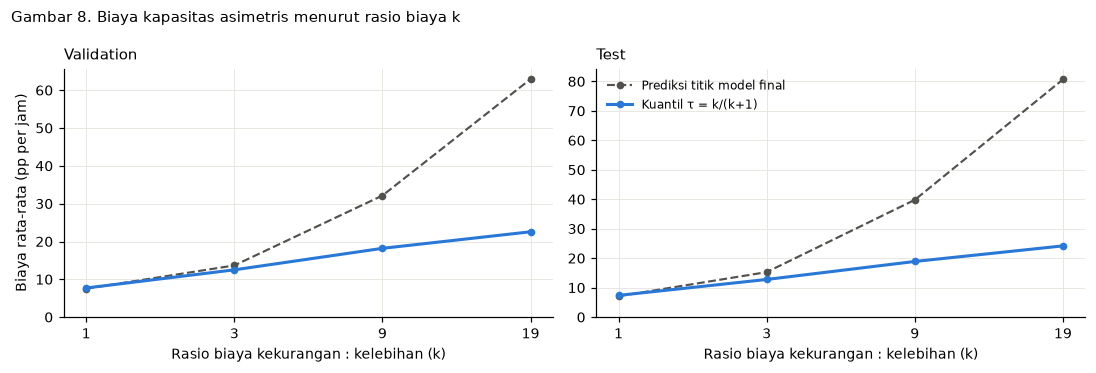

In [25]:
def cost(y, f, k): return k * np.clip(y - f, 0, None) + np.clip(f - y, 0, None)
rows = []
for ph, (d, M) in PROB.items():
    y = d.y.to_numpy()
    for k in K_COST:
        tau = k / (k + 1); j = int(np.argmin(np.abs(TAU - tau))); assert abs(TAU[j] - tau) < 1e-9
        fp, fq = d.point.to_numpy(), M[PROB_FINAL][:, j]; cp_, cq_ = cost(y, fp, k), cost(y, fq, k)
        r = dm_fixed_m(pd.Series(cq_ - cp_).groupby(d.origin.to_numpy()).mean().sort_index().to_numpy())
        rows.append({"Fase": FASE[ph], "k": k, "Kuantil τ": tau, "Biaya prediksi titik": cp_.mean(), "Biaya kuantil τ": cq_.mean(),
                     "Perubahan (%)": 100 * (cq_.mean() / cp_.mean() - 1), "CI 95% selisih": f"[{r['ci_lo']:+.2f}; {r['ci_hi']:+.2f}]", "p": r["p"],
                     "Kekurangan, titik (% jam)": 100 * np.mean(y > fp), "Kekurangan, kuantil (% jam)": 100 * np.mean(y > fq),
                     "Kelebihan rata-rata, kuantil (pp)": np.mean(np.clip(fq - y, 0, None)),
                     "Kesimpulan": "kuantil lebih murah" if r["ci_hi"] < 0 else "kuantil lebih mahal" if r["ci_lo"] > 0 else "tidak berbeda nyata"})
T15 = pd.DataFrame(rows); T15.to_csv(f"{OUT_DIR}/biaya_kapasitas.csv", index=False)
st = T15.style.hide(axis="index").format({"Kuantil τ": "{:.2f}", "Biaya prediksi titik": "{:.2f}", "Biaya kuantil τ": "{:.2f}", "Perubahan (%)": "{:+.1f}", "p": "{:.3f}",
                                          "Kekurangan, titik (% jam)": "{:.1f}", "Kekurangan, kuantil (% jam)": "{:.1f}", "Kelebihan rata-rata, kuantil (pp)": "{:.1f}"})
st = st.map(lambda v: "color: #1a7f4e; font-weight: 600" if v == "kuantil lebih murah" else "color: #c0392b; font-weight: 600" if v == "kuantil lebih mahal" else "", subset=["Kesimpulan"])
display(st.set_caption("Tabel 15. Biaya kapasitas asimetris: prediksi titik model final vs kuantil τ = k/(k+1) (biaya dalam pp per jam; makin kecil makin baik)")
          .set_table_styles([{"selector": "caption", "props": "caption-side: top; font-weight: 600; text-align: left;"}]))

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=False)
for ax, (ph, g) in zip(axs, T15.groupby("Fase", sort=False)):
    ax.plot(g.k.astype(str), g["Biaya prediksi titik"], color=INK2, ls="--", marker="o", ms=4, lw=1.4, label="Prediksi titik model final")
    ax.plot(g.k.astype(str), g["Biaya kuantil τ"], color=PCOL[PROB_FINAL], marker="o", ms=4, lw=2, label=f"Kuantil τ = k/(k+1)")
    ax.set_title(ph); ax.set_xlabel("Rasio biaya kekurangan : kelebihan (k)"); ax.set_ylim(0, None)
axs[0].set_ylabel("Biaya rata-rata (pp per jam)"); axs[1].legend(frameon=False, fontsize=8)
fig.suptitle("Gambar 8. Biaya kapasitas asimetris menurut rasio biaya k", x=.01, ha="left", fontsize=10)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/figures/08_biaya_kapasitas.png"); plt.show()

## 11. Kontribusi telemetri dari waktu ke waktu (TreeSHAP)

Di bagian 8 telemetri tidak terbukti menambah akurasi, dan di versi sebelumnya manfaatnya berubah antarperiode. Bagian ini melihat **mekanismenya**: seberapa besar model memakai telemetri pada tiap refit bulanan.
Kontribusi setiap fitur dihitung dengan TreeSHAP. Metode ini menghitung nilai Shapley secara eksak untuk model pohon, dan kontribusi semua fitur dijumlahkan menjadi prediksi (Lundberg dkk., 2020). Implementasinya memakai fungsi bawaan LightGBM.

- Model yang dijelaskan: **LightGBM · CPU + kalender + telemetri terpilih**, dengan konfigurasi dari seleksi beku, dilatih ulang pada setiap refit validation dan test.
- Untuk tiap refit diambil 6.000 baris prediksi secara acak. Rata-rata |kontribusi| fitur dijumlahkan per kelompok, lalu dinyatakan sebagai persentase dari total.
- Hasilnya disandingkan dengan selisih MAE bulanan antara Ensemble GBDT dengan dan tanpa telemetri. Kalau porsi kontribusi telemetri berubah sementara manfaatnya tidak konsisten, itu tanda model memakai hubungan yang bergeser antarperiode, yaitu *concept drift* (Bayram dkk., 2022).

Bagian ini **deskriptif**: menjelaskan perilaku model, bukan membuktikan sebab-akibat pada beban server.

In [26]:
SH_SPEC = BEST[("lgbm", "tele")]
def fit_model(sp, tr, start):
    f = FEATS[sp["fs"]]; ytr = (tr.y - tr.rata_4minggu).to_numpy(float) if sp["target"] == "resid" else tr.y.to_numpy(float)
    m = make_model(sp); m.fit(tr[f].to_numpy(np.float32), ytr, sample_weight=recency_w(tr, start, sp.get("hl"))); return m
def shap_phase(ph):
    key = sha_obj(["shap", ph, spec_key(SH_SPEC), FEATS[SH_SPEC["fs"]], [str(t) for t in ELIG], N_ITER, LR, VERSIONS, DATA_SHA, N_SHAP, SEED])[:12]
    path = f"{OUT_DIR}/cache/shap_{ph}_{key}.pkl"
    if REUSE_CACHE and os.path.exists(path): return pickle.load(open(path, "rb"))
    rng = np.random.default_rng(SEED); f = FEATS[SH_SPEC["fs"]]; rows = []
    for start, tr, te in folds(ph):
        m = fit_model(SH_SPEC, tr, start); idx = rng.choice(len(te), size=min(N_SHAP, len(te)), replace=False)
        con = m.predict(te[f].to_numpy(np.float32)[idx], pred_contrib=True)[:, :-1]          # kolom terakhir = nilai dasar
        rows.append({"refit": start, **dict(zip(f, np.abs(con).mean(axis=0)))})
    out = pd.DataFrame(rows); pickle.dump(out, open(path, "wb")); return out
def fgroup(c):
    if c.startswith("tele_"): m = c[5:]; return "Telemetri · sysload" if m.startswith("sysload") else "Telemetri · network" if m.startswith("network") else "Telemetri · disk"
    if c.startswith(("naif_", "rata_4minggu", "profil_jam_minggu", "anom", "dasar_plus")): return "Pola musiman & anomali"
    if c.startswith(("t_", "origin_")) or c == "h": return "Kalender & horizon"
    return "Riwayat CPU"
SHP = pd.concat([shap_phase("validation"), shap_phase("test")], ignore_index=True).set_index("refit")
GRP = SHP.T.groupby(SHP.columns.map(fgroup)).sum().T
SHARE = 100 * GRP.div(GRP.sum(axis=1), axis=0)
GORDER = ["Riwayat CPU", "Pola musiman & anomali", "Kalender & horizon", "Telemetri · sysload", "Telemetri · network", "Telemetri · disk"]
SHARE = SHARE[GORDER]; SHARE["Telemetri total"] = SHARE[GORDER[3:]].sum(axis=1)
mm = ALL.groupby("bulan").apply(lambda g: (g["ens|tele"] - g.y).abs().mean() - (g["ens|cpu"] - g.y).abs().mean())
T16 = SHARE.copy(); T16.insert(0, "Fase", ["Validation" if r < pd.Timestamp("2026-09-01") else "Test" for r in T16.index])
T16.insert(0, "Bulan", [r.strftime("%Y-%m") for r in T16.index]); T16["Selisih MAE ensemble: telemetri − CPU (pp)"] = [mm.get(r.strftime("%Y-%m"), np.nan) for r in T16.index]
T16 = T16.reset_index(drop=True); T16.to_csv(f"{OUT_DIR}/kontribusi_shap.csv", index=False)
show(T16, {c: "{:.1f}" for c in GORDER + ["Telemetri total"]} | {"Selisih MAE ensemble: telemetri − CPU (pp)": "{:+.2f}"},
     "Tabel 16. Porsi rata-rata |kontribusi SHAP| per kelompok fitur (%) per refit, dan selisih MAE bulanan (negatif = telemetri membantu)")
top = SHP.mean().sort_values(ascending=False).head(12)
show(pd.DataFrame({"Fitur": top.index, "Kelompok": [fgroup(c) for c in top.index], "Rata-rata |SHAP| (pp)": top.values}), {"Rata-rata |SHAP| (pp)": "{:.2f}"},
     "Tabel 17. Dua belas fitur dengan kontribusi terbesar (rata-rata semua refit)")

Bulan,Fase,Riwayat CPU,Pola musiman & anomali,Kalender & horizon,Telemetri · sysload,Telemetri · network,Telemetri · disk,Telemetri total,Selisih MAE ensemble: telemetri − CPU (pp)
2026-05,Validation,10.3,55.7,31.5,0.1,1.0,1.4,2.6,-0.07
2026-06,Validation,10.0,61.6,25.6,0.1,1.3,1.5,2.9,-0.07
2026-07,Validation,9.2,59.5,22.6,0.1,1.9,6.6,8.7,-0.59
2026-08,Validation,8.8,59.8,27.7,0.1,1.4,2.2,3.7,+0.05
2026-09,Test,8.8,61.2,23.4,0.2,1.3,5.1,6.6,+0.02
2026-10,Test,11.7,59.7,21.9,0.1,1.3,5.3,6.6,-0.17


Fitur,Kelompok,Rata-rata |SHAP| (pp)
profil_jam_minggu,Pola musiman & anomali,6.90
dasar_plus_anom_3,Pola musiman & anomali,3.74
dasar_plus_anom_12,Pola musiman & anomali,3.25
t_hari_ke_libur,Kalender & horizon,1.73
t_jam_cos,Kalender & horizon,1.07
t_tanggal,Kalender & horizon,0.88
t_jam,Kalender & horizon,0.81
tele_disk_read_iops_mean_168,Telemetri · disk,0.77
t_hari_ke_akhir_bulan,Kalender & horizon,0.71
naif_4minggu,Pola musiman & anomali,0.67


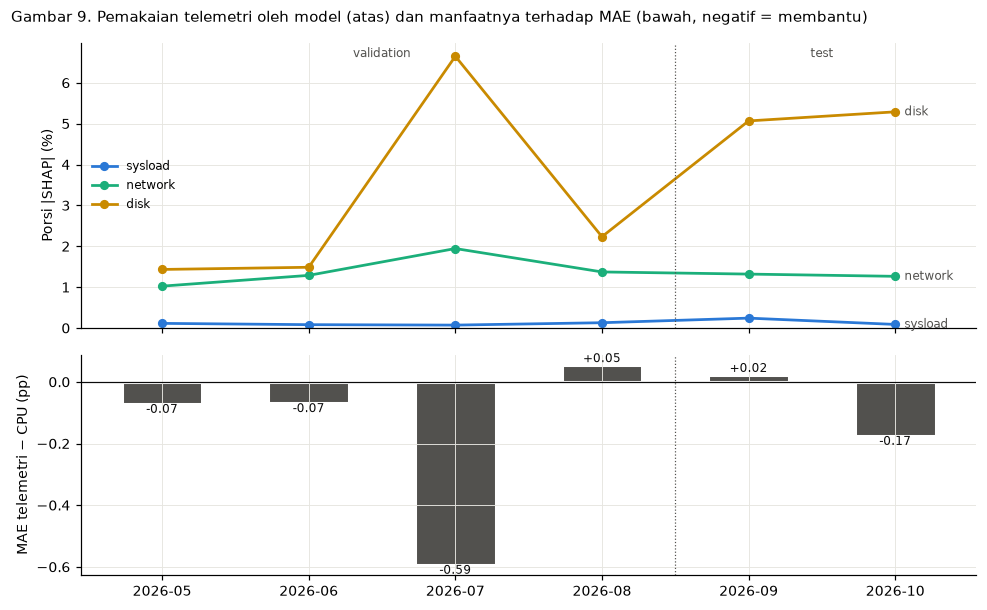

In [27]:
# Gambar 9: porsi kontribusi telemetri per bulan (atas) dan selisih MAE bulanan (bawah); dua panel, satu sumbu masing-masing
months = T16.Bulan.tolist(); x = np.arange(len(months)); TCOL = {"Telemetri · sysload": "#2a78d6", "Telemetri · network": "#1baf7a", "Telemetri · disk": "#c98a00"}
fig, axs = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
for g_, c in TCOL.items():
    axs[0].plot(x, T16[g_], color=c, marker="o", ms=5, lw=1.8, label=g_.replace("Telemetri · ", "")); axs[0].annotate(g_.replace("Telemetri · ", ""), (x[-1], T16[g_].iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=INK2)
axs[0].set_ylabel("Porsi |SHAP| (%)"); axs[0].set_ylim(0, None); axs[0].legend(frameon=False, fontsize=8, ncol=1, loc="center left")
d_ = T16["Selisih MAE ensemble: telemetri − CPU (pp)"].to_numpy()
axs[1].bar(x, d_, color=INK2, width=.55, edgecolor="white", linewidth=2); axs[1].axhline(0, color=INK, lw=.8)
for xi, v in zip(x, d_): axs[1].text(xi, v, f"{v:+.2f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=8, color=INK)
axs[1].set_ylabel("MAE telemetri − CPU (pp)"); axs[1].set_xticks(x, months)
for ax in axs: ax.axvline(3.5, color=INK2, ls=":", lw=.8)
axs[0].text(1.5, axs[0].get_ylim()[1] * .95, "validation", ha="center", fontsize=8, color=INK2); axs[0].text(4.5, axs[0].get_ylim()[1] * .95, "test", ha="center", fontsize=8, color=INK2)
fig.suptitle("Gambar 9. Pemakaian telemetri oleh model (atas) dan manfaatnya terhadap MAE (bawah, negatif = membantu)", x=.01, ha="left", fontsize=10)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/figures/09_kontribusi_telemetri.png"); plt.show()

## 12. Pra-registrasi uji konfirmasi (versi 3)

Uji konfirmasi memakai data **setelah 1 November 2026**, yang nilainya belum dibaca.
Rencana ini dibekukan dengan hash sebelum data itu dievaluasi, dan sel ini menolak menimpanya.

**Riwayat.** Versi 1 (8 Nov 2026 13:09) dan versi 2 (8 Nov 2026 14:05) dibuat dengan pipeline v2. Keduanya digantikan sebelum data konfirmasi dievaluasi, karena pipeline diganti dengan notebook v3 ini.
Hash kedua versi lama dicatat di dalam file versi 3.

In [28]:
PRE = f"{OUT_DIR}/prereg_konfirmasi_v3.json"
if not os.path.exists(PRE):
    pre = {"versi": 3, "dibuat": time.strftime("%Y-%m-%d %H:%M:%S"), "status": "dibekukan sebelum data konfirmasi dievaluasi",
           "riwayat": [{"versi": 1, "dibuat": "2026-11-08 13:09:43", "sha256": "f8600378da22c95951d34ff71b99ac279b5895d10d527a33cc4b7d13e6e9fd64", "alasan_diganti": "pembersihan data kosong ditambahkan"},
                       {"versi": 2, "dibuat": "2026-11-08 14:05:01", "sha256": "289111e54ac323eded7b93564b8669f75da8aa28ef7b9f326cc27b2fa4f8773e", "alasan_diganti": "pipeline diganti notebook v3 (kalender library holidays, telemetri terpilih, iterasi boosting tetap, uji DM)"}],
           "seleksi_beku_sha256": open(SEL_PATH + ".sha256").read().strip(), "model_final": NAME[FINAL],
           "kandidat": {"A": NAME["ens|cpu"], "B": NAME["ens|tele"], "konfigurasi": sel["konfigurasi_terbaik"]},
           "data": {"origin_pertama": "2026-11-01 00:00 (semua targetnya setelah batas data)", "syarat_jalan": "minimal 28 hari origin dinilai: data CPU lengkap sampai >= 2026-12-04 00:00",
                    "refit": "model dilatih ulang tiap tanggal 1 dengan label yang sudah matang; data training = semua data sampai waktu refit"},
           "pembersihan": sel["pembersihan"], "telemetri": TELE, "kalender": sel["kalender"],
           "uji": "Diebold-Mariano fixed-m (Coroneo & Iacone, 2020), m = floor(T^(1/3)), t(2m), selisih MAE per origin",
           "aturan_keputusan": [f"Hipotesis utama: MAE({NAME['ens|tele']}) - MAE({NAME['ens|cpu']}) < 0.",
                                "Bila CI 95% atas < 0: telemetri terbukti membantu; model operasional = ensemble dengan telemetri.",
                                "Selain itu: model operasional = ensemble CPU + kalender (lebih sederhana, tidak bergantung pada pengumpulan telemetri).",
                                "Bila lebih dari 50% origin konfirmasi memakai fallback C3: telemetri dianggap tidak andal; model operasional = ensemble CPU + kalender."],
           "dilaporkan_tanpa_keputusan": ["model final vs Rata-rata 4 minggu dan Naif musiman mingguan (uji DM)", "MAE per pita horizon dan per bulan", "MAE dan bias puncak (CPU >= 80%)", "jumlah origin fallback dan origin dengan target tidak lengkap"],
           "larangan": "tidak ada tuning, perubahan fitur, atau pemilihan ulang setelah data konfirmasi dilihat; analisis tambahan ditandai eksploratori"}
    json.dump(pre, open(PRE, "w"), indent=2, default=str); open(PRE + ".sha256", "w").write(sha_file(PRE))
assert sha_file(PRE) == open(PRE + ".sha256").read().strip(), "pra-registrasi berubah setelah dibekukan!"
pre = json.load(open(PRE)); assert pre["seleksi_beku_sha256"] == open(SEL_PATH + ".sha256").read().strip(), "seleksi berubah setelah pra-registrasi!"
rows = [("Versi", f"{pre['versi']} (dibuat {pre['dibuat']})"), ("Menggantikan", "; ".join(f"v{r['versi']} {r['dibuat']} ({r['alasan_diganti']})" for r in pre["riwayat"])),
        ("Seleksi beku", pre["seleksi_beku_sha256"][:16] + "…"), ("Model final", pre["model_final"]), ("Kandidat A", pre["kandidat"]["A"]), ("Kandidat B", pre["kandidat"]["B"]),
        ("Telemetri", ", ".join(pre["telemetri"])), ("Data", pre["data"]["syarat_jalan"]), ("Uji", pre["uji"])] + \
       [(f"Aturan {i + 1}", a) for i, a in enumerate(pre["aturan_keputusan"])] + [("Larangan", pre["larangan"]), ("SHA-256", open(PRE + ".sha256").read()[:16] + "…")]
show(pd.DataFrame(rows, columns=["Butir", "Isi"]), {}, "Tabel 18. Ringkasan pra-registrasi uji konfirmasi")

Butir,Isi
Versi,3 (dibuat 2026-11-10 22:49:37)
Menggantikan,"v1 2026-11-08 13:09:43 (pembersihan data kosong ditambahkan); v2 2026-11-08 14:05:01 (pipeline diganti notebook v3 (kalender library holidays, telemetri terpilih, iterasi boosting tetap, uji DM))"
Seleksi beku,abe693959840af47…
Model final,Ensemble GBDT · CPU + kalender + telemetri terpilih
Kandidat A,Ensemble GBDT · CPU + kalender
Kandidat B,Ensemble GBDT · CPU + kalender + telemetri terpilih
Telemetri,"sysload_1m, sysload_15m, network_rx_bytes_per_sec, network_tx_bytes_per_sec, disk_read_bytes_per_sec, disk_write_bytes_per_sec, disk_read_iops, disk_write_iops"
Data,minimal 28 hari origin dinilai: data CPU lengkap sampai >= 2026-12-04 00:00
Uji,"Diebold-Mariano fixed-m (Coroneo & Iacone, 2020), m = floor(T^(1/3)), t(2m), selisih MAE per origin"
Aturan 1,Hipotesis utama: MAE(Ensemble GBDT · CPU + kalender + telemetri terpilih) - MAE(Ensemble GBDT · CPU + kalender) < 0.


### 12.1 Amandemen 1: outcome sekunder (bagian 9–11)

Amandemen ini **menambah** outcome sekunder tanpa mengubah hipotesis utama, kandidat, atau aturan keputusan versi 3.
Amandemen dibuat sebelum data konfirmasi lengkap (sebelum 4 Des 2026) dan dikunci dengan hash. Hash pra-registrasi v3 dan seleksi probabilistik dicatat di dalamnya.

In [29]:
AMD = f"{OUT_DIR}/prereg_konfirmasi_v3_amandemen1.json"
if not os.path.exists(AMD):
    assert pd.Timestamp.now() < pd.Timestamp("2026-12-04"), "amandemen hanya boleh dibuat sebelum data konfirmasi lengkap"
    amd = {"amandemen": 1, "dibuat": time.strftime("%Y-%m-%d %H:%M:%S"), "prereg_v3_sha256": open(PRE + ".sha256").read().strip(),
           "seleksi_probabilistik_sha256": open(PSEL_PATH + ".sha256").read().strip(), "hipotesis_utama": "tidak berubah (lihat prereg v3)",
           "outcome_sekunder": [
               {"nama": "S1 prediksi probabilistik", "metode": PNAME[PROB_FINAL], "kuantil": QLEVELS, "jendela_kalibrasi_hari": WINDOW_DAYS,
                "dilaporkan": "skor kuantil rata-rata, cakupan interval 80% dan 90% (dibanding nominal), lebar, skor Winkler, kalibrasi per kuantil",
                "fallback": "origin dengan outage telemetri memakai metode EnbPI pada prediksi titik fallback"},
               {"nama": "S2 biaya kapasitas asimetris", "k": K_COST, "aturan": "untuk k = 3, 9, 19: kuantil tau = k/(k+1) dinilai lebih murah daripada prediksi titik model final bila CI 95% atas selisih biaya per origin < 0 (uji DM fixed-m)",
                "dilaporkan": "biaya rata-rata, % jam kekurangan, kelebihan rata-rata"},
               {"nama": "S3 kontribusi telemetri (TreeSHAP)", "dilaporkan": "porsi |SHAP| per kelompok fitur per refit; deskriptif, tanpa uji"}],
           "larangan": "tidak ada perubahan metode, kuantil, jendela, atau rasio k setelah data konfirmasi dilihat"}
    json.dump(amd, open(AMD, "w"), indent=2, default=str); open(AMD + ".sha256", "w").write(sha_file(AMD))
assert sha_file(AMD) == open(AMD + ".sha256").read().strip(), "amandemen berubah setelah dibekukan!"
amd = json.load(open(AMD)); assert amd["prereg_v3_sha256"] == open(PRE + ".sha256").read().strip() and amd["seleksi_probabilistik_sha256"] == open(PSEL_PATH + ".sha256").read().strip()
rows = [("Dibuat", amd["dibuat"]), ("Pra-registrasi v3", amd["prereg_v3_sha256"][:16] + "…"), ("Hipotesis utama", amd["hipotesis_utama"])] + \
       [(o["nama"], o.get("metode", "") + (" · " if o.get("metode") else "") + o.get("aturan", o["dilaporkan"])) for o in amd["outcome_sekunder"]] + \
       [("Larangan", amd["larangan"]), ("SHA-256", open(AMD + ".sha256").read()[:16] + "…")]
show(pd.DataFrame(rows, columns=["Butir", "Isi"]), {}, "Tabel 19. Amandemen 1 pra-registrasi")

Butir,Isi
Dibuat,2026-11-10 22:49:37
Pra-registrasi v3,f7b9064ec96bf561…
Hipotesis utama,tidak berubah (lihat prereg v3)
S1 prediksi probabilistik,"Prediksi titik model final + kuantil galat terkini (EnbPI) · skor kuantil rata-rata, cakupan interval 80% dan 90% (dibanding nominal), lebar, skor Winkler, kalibrasi per kuantil"
S2 biaya kapasitas asimetris,"untuk k = 3, 9, 19: kuantil tau = k/(k+1) dinilai lebih murah daripada prediksi titik model final bila CI 95% atas selisih biaya per origin < 0 (uji DM fixed-m)"
S3 kontribusi telemetri (TreeSHAP),"porsi |SHAP| per kelompok fitur per refit; deskriptif, tanpa uji"
Larangan,"tidak ada perubahan metode, kuantil, jendela, atau rasio k setelah data konfirmasi dilihat"
SHA-256,84c91c5a509e3cc7…


## 13. Kesimpulan

Angka dikutip dari tabel di atas (run 8 Nov 2026). Hasil validation adalah dasar seleksi. Hasil test bersifat eksploratori.

> **Perlu diperbarui setelah dijalankan ulang:** bagian 8.3 (Ridge), 8.4 (weighted loss puncak), dan Tabel 12d–12e (stabilitas) ditambahkan 11 Nov 2026 dan angkanya belum ada di kesimpulan ini.

**Prediksi titik (bagian 1–8)**
1. **Data dan pembersihan.** Dinilai 473 origin validation dan 225 origin test, masing-masing × 120 horizon. Semua uji kebocoran lolos, dan tidak ada origin yang memakai fallback (Tabel 6, 7a–7b).
2. **Telemetri.** Delapan metrik dipakai: sysload, network, dan disk. Memory, swap, process_running, dan process_blocked dibuang karena tidak lagi tersedia, sering kosong, atau korelasinya rendah (Tabel 4).
3. **Model final** (dipilih di validation): **Ensemble GBDT · CPU + kalender + telemetri terpilih**.
   - Validation: MAE 7,61 pp, atau 0,84 kali pembanding rata-rata 4 minggu.
   - Lebih akurat secara nyata daripada rata-rata 4 minggu (−1,43 pp, CI [−2,80; −0,07]) (Tabel 10–11).
4. **Telemetri vs CPU saja tidak berbeda nyata:** validation −0,08 pp (CI [−0,40; +0,23]), test −0,06 pp (CI [−0,30; +0,19]). Keputusan akhirnya diserahkan ke uji konfirmasi.
5. **Test.** MAE model final 7,14 pp. Keunggulan atas rata-rata 4 minggu **tidak nyata** (−0,48 pp, CI [−1,15; +0,20]), karena Oktober adalah bulan yang sangat teratur (Tabel 12b).
6. **Antarmodel dan horizon.** Ensemble setara dengan model tunggal terbaik (Wang dkk., 2023). Galat naik sedikit seiring horizon (Gambar 2). Perbandingan dengan Ridge musiman multivariat ada di bagian 8.3 (Tabel 12f–12h).

**Prediksi probabilistik (bagian 9)**

7. **Kalibrasi diperlukan.** LightGBM kuantil tanpa kalibrasi memberi interval yang terlalu sempit: cakupan interval 80% hanya 66,7% di validation dan 72,1% di test (Tabel 13).
   - Kedua metode kalibrasi konformal membawa cakupan mendekati nominal (Gambar 6).
   - Metode terpilih: **prediksi titik model final + kuantil galat terkini (EnbPI)**.
   - Skor kuantil validation ketiga metode hampir sama: 4,589, 4,591, dan 4,604.
   - Cakupan metode terpilih untuk interval 80% dan 90%: 77,6% dan 88,0% di validation, 78,7% dan 89,4% di test.
   - Di test, LightGBM kuantil tanpa kalibrasi justru mendapat skor kuantil terendah (4,16 vs 4,33) karena intervalnya lebih sempit, tetapi cakupannya kurang. Ini dilaporkan apa adanya, karena seleksi hanya memakai validation.
8. **Puncak.** Kuantil 0,95 dari metode terpilih berada di atas nilai aktual pada 76% jam puncak validation dan 52% jam puncak test. Prediksi titik hampir selalu menaksir puncak terlalu rendah (bias puncak −9 dan −16 pp). Puncak test tetap sulit, karena 63% baris puncaknya berasal dari satu pekan (Tabel 12c).

**Biaya kapasitas (bagian 10)**

9. **Kuantil jauh lebih murah bila kekurangan kapasitas mahal.** Untuk k ≥ 9 (kekurangan ≥ 9 kali lebih mahal daripada kelebihan), merencanakan kapasitas dengan kuantil τ = k/(k+1) jauh lebih murah daripada prediksi titik (Tabel 15, Gambar 8), dan semuanya berbeda nyata:
   - Validation: −44% (k = 9) dan −65% (k = 19).
   - Test: −53% (k = 9) dan −70% (k = 19).
   - Untuk k = 3, penghematannya nyata hanya di test (−16%). Untuk k = 1 tidak ada beda.
   - Dengan kuantil 0,95, jam kekurangan kapasitas turun dari 44–52% menjadi sekitar 6%, dengan cadangan rata-rata sekitar 16 pp.
   - Rasio *k* yang sebenarnya perlu ditetapkan bersama pengelola server.

**Kontribusi telemetri (bagian 11)**

10. **Model terutama memakai pola musiman dan kalender.** Pola musiman dan anomali menyumbang 56–61% dari total |SHAP|, kalender dan horizon 22–32%, dan telemetri hanya 2–7,5% (Tabel 16).
    - Telemetri yang dipakai terutama dari metrik disk. Sysload hampir nol, karena informasinya sudah terwakili riwayat CPU.
    - Porsi telemetri tertinggi (Juli, 7,5%) bertepatan dengan satu-satunya bulan dengan manfaat besar (−0,62 pp).
    - Tetapi September juga memakai telemetri cukup banyak (6,8%) tanpa manfaat (+0,07 pp) (Gambar 9).
    - Jadi pemakaian telemetri oleh model tidak konsisten menghasilkan akurasi. Ini sejalan dengan temuan bahwa manfaatnya tidak stabil (Bayram dkk., 2022).
11. **Kalender libur berpengaruh.** **Jarak ke hari libur** adalah fitur terpenting keempat (Tabel 17). Ini bukti awal bahwa kalender libur dan cuti bersama Indonesia memengaruhi beban server.

**Langkah berikutnya**

12. Uji konfirmasi sesuai **pra-registrasi v3 dan amandemen 1**, dijalankan setelah data CPU lengkap sampai 4 Des 2026:
    - hipotesis utama: telemetri vs CPU saja,
    - outcome sekunder: cakupan interval, biaya kapasitas, dan kontribusi telemetri.

## Daftar pustaka

**Jurnal (2020–2025)** — Ribeiro & Moniz (2020) ditambahkan untuk bagian 8.4.
1. Bayram, F., Ahmed, B. S., & Kassler, A. (2022). From concept drift to model degradation: An overview on performance-aware drift detectors. *Knowledge-Based Systems, 245*, 108632. https://doi.org/10.1016/j.knosys.2022.108632
2. Bentéjac, C., Csörgő, A., & Martínez-Muñoz, G. (2021). A comparative analysis of gradient boosting algorithms. *Artificial Intelligence Review, 54*(3), 1937–1967. https://doi.org/10.1007/s10462-020-09896-5
3. Cerqueira, V., Torgo, L., & Mozetič, I. (2020). Evaluating time series forecasting models: An empirical study on performance estimation methods. *Machine Learning, 109*, 1997–2028. https://doi.org/10.1007/s10994-020-05910-7
4. Coroneo, L., & Iacone, F. (2020). Comparing predictive accuracy in small samples using fixed-smoothing asymptotics. *Journal of Applied Econometrics, 35*(4), 391–409. https://doi.org/10.1002/jae.2756
5. Eramo, V., Lavacca, F. G., Catena, T., & Di Giorgio, F. (2020). Reconfiguration of optical-NFV network architectures based on cloud resource allocation and QoS degradation cost-aware prediction techniques. *IEEE Access, 8*, 200834–200850.
6. Hewamalage, H., Ackermann, K., & Bergmeir, C. (2023). Forecast evaluation for data scientists: Common pitfalls and best practices. *Data Mining and Knowledge Discovery, 37*(2), 788–832. https://doi.org/10.1007/s10618-022-00894-5
7. Hewamalage, H., Bergmeir, C., & Bandara, K. (2021). Recurrent neural networks for time series forecasting: Current status and future directions. *International Journal of Forecasting, 37*(1), 388–427. https://doi.org/10.1016/j.ijforecast.2020.06.008
8. Januschowski, T., Wang, Y., Torkkola, K., Erkkilä, T., Hasson, H., & Gasthaus, J. (2022). Forecasting with trees. *International Journal of Forecasting, 38*(4), 1473–1481. https://doi.org/10.1016/j.ijforecast.2021.10.004
9. Kolassa, S. (2020). Why the "best" point forecast depends on the error or accuracy measure. *International Journal of Forecasting, 36*(1), 208–211. https://doi.org/10.1016/j.ijforecast.2019.02.017
10. Lundberg, S. M., dkk. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence, 2*(1), 56–67. https://doi.org/10.1038/s42256-019-0138-9
11. Makridakis, S., Spiliotis, E., & Assimakopoulos, V. (2022a). M5 accuracy competition: Results, findings, and conclusions. *International Journal of Forecasting, 38*(4), 1346–1364. https://doi.org/10.1016/j.ijforecast.2021.11.013
12. Makridakis, S., Spiliotis, E., Assimakopoulos, V., Chen, Z., Gaba, A., Tsetlin, I., & Winkler, R. L. (2022b). The M5 uncertainty competition: Results, findings and conclusions. *International Journal of Forecasting, 38*(4), 1365–1385. https://doi.org/10.1016/j.ijforecast.2021.10.009
13. Petropoulos, F., dkk. (2022). Forecasting: Theory and practice. *International Journal of Forecasting, 38*(3), 705–871. https://doi.org/10.1016/j.ijforecast.2021.11.001
14. Rossi, A., Visentin, A., Carraro, D., Prestwich, S., & Brown, K. N. (2025). Forecasting workload in cloud computing: Towards uncertainty-aware predictions and transfer learning. *Cluster Computing, 28*(4), 258. https://doi.org/10.1007/s10586-024-04933-2
15. Ribeiro, R. P., & Moniz, N. (2020). Imbalanced regression and extreme value prediction. *Machine Learning, 109*(9–10), 1803–1835. https://doi.org/10.1007/s10994-020-05900-9
16. Saxena, D., Kumar, J., Singh, A. K., & Schmid, S. (2023). Performance analysis of machine learning centered workload prediction models for cloud. *IEEE Transactions on Parallel and Distributed Systems, 34*(4), 1313–1330. https://doi.org/10.1109/TPDS.2023.3240567
17. Wang, X., Hyndman, R. J., Li, F., & Kang, Y. (2023). Forecast combinations: An over 50-year review. *International Journal of Forecasting, 39*(4), 1518–1547. https://doi.org/10.1016/j.ijforecast.2022.11.005
18. Xu, C., & Xie, Y. (2023). Conformal prediction for time series. *IEEE Transactions on Pattern Analysis and Machine Intelligence, 45*(10). https://doi.org/10.1109/TPAMI.2023.3272339

**Buku (2021)**
19. Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3rd ed.). OTexts. https://otexts.com/fpp3/ — bagian yang dirujuk: §5.2, §5.8, §5.9, §5.10, §7.4, §7.5, §8.1, §13.1, §13.4, §13.9.
20. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An introduction to statistical learning* (2nd ed.). Springer. https://doi.org/10.1007/978-1-0716-1418-1 — §6.2.

**Perangkat lunak:** holidays (kalender Indonesia), scikit-learn, LightGBM, XGBoost, pandas, NumPy, SciPy, Matplotlib. Versinya tercantum di bagian 0.

Petropoulos dkk. (2022) dipakai sebagai rujukan umum untuk keseluruhan praktik forecasting di notebook ini.